# Task 4 — Real-World Dataset Analysis: UCI Online Retail
**Author: T. Aparna Reddy** · Revised evidence-based submission · 7 November 2026

This executed notebook uses the unchanged genuine UCI workbook. No synthetic records,
claimed campaign outcomes or substitute dataset are used. All figures, worked arithmetic,
cleaned exports and aggregate CSVs are generated by the companion Python source.

Source: Chen, D. (2015), *Online Retail*, UCI. DOI: 10.24432/C5BW33. CC BY 4.0.
The report follows all 19 requested sections; this notebook follows the computational workflow.


## 1. Execute the full, verified analysis
The workbook SHA-256 must match before calculations begin. `runpy` exposes the real
frames and calculations for the exploratory cells below. Notebook execution is configured
to stop on error; displayed outputs are actual execution outputs.

In [1]:
from pathlib import Path
import json
import runpy
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT/'scripts/analyze.py').exists():
    ROOT = ROOT.parent
ns = runpy.run_path(str(ROOT/'scripts/analyze.py'))
raw, clean, sales = ns['raw'], ns['clean'], ns['sales']
invoice, customers = ns['invoice'], ns['customers']
m, e = ns['m'], ns['extra']
del ns
import gc
gc.collect()
print('Raw:', raw.shape, '| cleaned-all:', clean.shape, '| sales:', sales.shape)
print('Source SHA-256:', m['sha256'])

gross_sales: 10642110.8
credit_value_abs: 893979.73
credit_adjusted_value: 9748131.07
other_excluded_value: -22124.12
dedup_signed_all_lines: 9726006.95
known_customer_sales: 8887208.89
anonymous_sales_share_pct: 16.49
champions_total_sales_share_pct: 53.84
largest_nonuk_country: Netherlands
paired_extreme_gross: 245653.2
PASS: 24 Task 4 metric reconciliations; all aggregation and partition checks.


Extended exploration complete: [536641, 16] cleaned-all; [524878, 16] qualified sales
Description whitespace normalized: 112371 | Country whitespace: 0
Raw mean / min Quantity: 9.55224954743324 -80995
Worked standard deviation: 0.8944271909999159
Worked Pearson r: 0.9952659485651739 | Worked Welch t: -5.474116123522671 df: 1008.1829680542309 p: 5.549594300098356e-08
Quantity IQR outliers: 27111 | first invoice: 139.12
Raw: (541909, 8) | cleaned-all: (536641, 16) | sales: (524878, 16)
Source SHA-256: 43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d


## 2. Raw schema, missingness, uniqueness and genuine records
IDs are nominal, even when imported as numeric. CustomerID is not described with a
meaningless mean/SD. Missing values and duplicate percentages use the raw-row denominator.

In [2]:
display(pd.read_csv(ROOT/'outputs/raw_schema_profile.csv'))
display(raw.head(10))
print('Exact duplicate rows:', raw.duplicated().sum())
print('Duplicate %:', raw.duplicated().mean()*100)
print('Raw CustomerID missing %:', raw.CustomerID.isna().mean()*100)

,Column,RawDtype,Role,NonNull,Missing,MissingPct,UniqueNonNull
0,InvoiceNo,object,nominal invoice/credit identifier,541909,0,0.000000,25900
1,StockCode,object,nominal item/service identifier,541909,0,0.000000,4070
2,Description,object,categorical text label,540455,1454,0.268311,4223
3,Quantity,int64,numeric signed measure,541909,0,0.000000,722
4,InvoiceDate,datetime64[ns],"datetime, source timezone unspecified",541909,0,0.000000,23260
5,UnitPrice,float64,numeric GBP measure,541909,0,0.000000,1630
6,CustomerID,float64,"nullable nominal identifier, not a monetary/qu...",406829,135080,24.926694,4372
7,Country,object,categorical customer-country label,541909,0,0.000000,38


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


Exact duplicate rows: 5268
Duplicate %: 0.9721189350979592
Raw CustomerID missing %: 24.926694334288598


In [3]:
display(pd.read_csv(ROOT/'outputs/raw_descriptive_statistics.csv'))
display(pd.read_csv(ROOT/'outputs/valid_descriptive_statistics.csv'))
for name in ['raw_country_frequencies.csv', 'raw_stockcode_frequencies.csv',
             'raw_description_frequencies.csv']:
    print(name)
    display(pd.read_csv(ROOT/'outputs'/name).head(10))

,Variable,Grain,Count,Mean,Median,FirstMode,NumberOfModes,StdSample,VarianceSample,Minimum,Q1,Q3,IQR,Maximum,P95,P99,Skewness
0,Quantity,raw invoice line,541909,9.552250,3.00,1.00,1,218.081158,47559.391409,-80995.00,1.00,10.00,9.00,80995.0,29.00,100.0,-0.264076
1,UnitPrice,raw invoice line,541909,4.611114,2.08,1.25,1,96.759853,9362.469164,-11062.06,1.25,4.13,2.88,38970.0,9.95,18.0,186.506972
2,Derived signed line value,raw invoice line,541909,17.987795,9.75,15.00,1,378.810824,143497.640005,-168469.60,3.40,17.40,14.00,168469.6,59.40,180.0,-0.964389


,Variable,Grain,Count,Mean,Median,FirstMode,NumberOfModes,StdSample,VarianceSample,Minimum,Q1,Q3,IQR,Maximum,P95,P99,Skewness
0,Quantity,qualified sales line,524878,10.616600,4.00,1.00,1,156.280031,2.442345e+04,1.000,1.000,11.0000,10.0000,80995.00,30.000,100.0000,469.541785
1,UnitPrice,qualified sales line,524878,3.922573,2.08,1.25,1,36.093028,1.302707e+03,0.001,1.250,4.1300,2.8800,13541.33,9.950,16.9800,205.085168
2,LineValue,qualified sales line,524878,20.275399,9.92,15.00,1,271.693566,7.381739e+04,0.001,3.900,17.7000,13.8000,168469.60,59.800,183.6000,504.232562
3,InvoiceValue,qualified sales invoice,19960,533.171884,303.30,15.00,1,1780.412288,3.169868e+06,0.380,151.695,493.4625,341.7675,168469.60,1585.921,4821.1654,51.077769


raw_country_frequencies.csv


,Category,Frequency,RawLineSharePct
0,United Kingdom,495478,91.431956
1,Germany,9495,1.752139
2,France,8557,1.579047
3,EIRE,8196,1.512431
4,Spain,2533,0.467422
5,Netherlands,2371,0.437527
6,Belgium,2069,0.381798
7,Switzerland,2002,0.369435
8,Portugal,1519,0.280305
9,Australia,1259,0.232327


raw_stockcode_frequencies.csv


,Category,Frequency,RawLineSharePct
0,85123A,2313,0.426824
1,22423,2203,0.406526
2,85099B,2159,0.398406
3,47566,1727,0.318688
4,20725,1639,0.302449
5,84879,1502,0.277168
6,22720,1477,0.272555
7,22197,1476,0.272370
8,21212,1385,0.255578
9,20727,1350,0.249119


raw_description_frequencies.csv


,Category,Frequency,RawLineSharePct
0,WHITE HANGING HEART T-LIGHT HOLDER,2369,0.437158
1,REGENCY CAKESTAND 3 TIER,2200,0.405972
2,JUMBO BAG RED RETROSPOT,2159,0.398406
3,PARTY BUNTING,1727,0.318688
4,LUNCH BAG RED RETROSPOT,1638,0.302265
5,ASSORTED COLOUR BIRD ORNAMENT,1501,0.276984
6,SET OF 3 CAKE TINS PANTRY DESIGN,1473,0.271817
7,NaN,1454,0.268311
8,PACK OF 72 RETROSPOT CAKE CASES,1385,0.255578
9,LUNCH BAG BLACK SKULL.,1350,0.249119


## 3. Cleaning audit and complete exports
Deduplication is an assumption, with a no-dedup sensitivity. Labels/types are normalized
without erasing authentic credits, anonymous sales or unusual quantities. Positive sales
are a named view, not a replacement for the full cleaned dataset.

In [4]:
display(pd.read_csv(ROOT/'outputs/cleaning_step_audit.csv'))
display(pd.read_csv(ROOT/'outputs/exclusive_line_partitions.csv'))
display(pd.read_csv(ROOT/'outputs/description_format_examples.csv').head())
display(pd.read_csv(ROOT/'outputs/negative_price_exceptions.csv'))
print('Known customer IDs missing after cleaning:', clean.CustomerID.isna().sum())
print('Null descriptions after sentinel:', clean.Description.isna().sum())
print('Cleaned payload duplicates:', clean.drop(columns='SourceRow').duplicated().sum())
print('No-dedup sales:', m['raw_valid_sales_sensitivity'])
print('Deduplicated sales:', m['gross_sales'])

,Operation,RowsBefore,RowsAfter,AffectedOrFlagged,Code,ReasonAndEffect
0,Exact duplicate source rows,541909,536641,5268,raw.drop_duplicates(),Assumption: identical source rows are duplicat...
1,InvoiceNo / StockCode types,536641,536641,0,astype('string').str.strip(),"Nominal identifiers, no financial values or ro..."
2,CustomerID nullable integer,536641,536641,135037,CustomerID.astype('Int64'),Lossless integer IDs; missing IDs remain missi...
3,Missing Description,536641,536641,1454,Description.fillna('UNKNOWN'),Sentinel only; does not claim to recover the p...
4,Description edge whitespace,536641,536641,112371,Description.str.strip(),Formatting only; product aggregation uses Stoc...
5,Country edge whitespace,536641,536641,0,Country.str.strip(),Measured count may be zero; no invented countr...
6,InvoiceDate validation,536641,536641,0,"pd.to_datetime(..., errors='coerce')",Original datetime is already valid; assert no ...
7,C-credit flag / partition,536641,536641,9251,InvoiceNo.str.upper().str.startswith('C'),Retain credits in cleaned-all; separate from q...
8,Qualified positive sales filter,536641,524878,11763,(~IsCredit) & (Quantity > 0) & (UnitPrice > 0),"Create a separate view, not deletion from clea..."
9,IQR quantity / price flags,524878,524878,27111,Q1 - 1.5*IQR; Q3 + 1.5*IQR,"Flag, inspect and retain all qualified outlier..."


,Partition,Lines,DistinctInvoicesInPartition,SignedValue
0,Positive-price non-credit sales,524878,19960,1.064211e+07
1,C-prefixed credit notes,9251,3836,-8.939797e+05
2,Other negative-quantity movements,1336,1336,0.000000e+00
3,Remaining excluded lines,1176,821,-2.212412e+04


,SourceRow,Before,After
0,12,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE BEDROOM
1,15,IVORY KNITTED MUG COSY,IVORY KNITTED MUG COSY
2,17,BOX OF VINTAGE JIGSAW BLOCKS,BOX OF VINTAGE JIGSAW BLOCKS
3,29,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE RED
4,32,STARS GIFT TAPE,STARS GIFT TAPE


,InvoiceNo,StockCode,Description,InvoiceDate,Quantity,UnitPrice,LineValue
0,A563186,B,Adjust bad debt,2011-08-12 14:51:00,1,-11062.06,-11062.06
1,A563187,B,Adjust bad debt,2011-08-12 14:52:00,1,-11062.06,-11062.06


Known customer IDs missing after cleaning: 135037
Null descriptions after sentinel: 0


Cleaned payload duplicates: 0
No-dedup sales: 10666684.54
Deduplicated sales: 10642110.8


## 4. Worked examples: actual line and complete invoice
Line value is quantity × recorded unit amount. The first invoice has seven qualified
lines; line counts must not be mistaken for independent order counts.

In [5]:
first = pd.read_csv(ROOT/'outputs/worked_invoice_536365.csv')
display(first)
print('First recorded line: 6 * 2.55 =', 6*2.55)
print('Invoice 536365 sum:', round(first.LineValue.sum(), 2))
assert np.isclose(first.LineValue.sum(), 139.12)
print('AOV:', sales.LineValue.sum()/invoice.InvoiceNo.nunique())
values = np.sort(invoice.InvoiceValue.to_numpy())
print('Median centre positions 9980 and 9981:', values[9979], values[9980])
print('CustomerID missing:', 135080/541909*100, '%')
print('Duplicates:', 5268/541909*100, '%')

,SourceRow,InvoiceNo,StockCode,Description,Quantity,UnitPrice,LineValue
0,2,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,3,536365,71053,WHITE METAL LANTERN,6,3.39,20.34
2,4,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,5,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,6,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34
5,7,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,7.65,15.30
6,8,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,4.25,25.50


First recorded line: 6 * 2.55 = 15.299999999999999
Invoice 536365 sum: 139.12
AOV: 533.171883967936
Median centre positions 9980 and 9981: 303.3 303.3
CustomerID missing: 24.926694334288598 %
Duplicates: 0.9721189350979592 %


## 5. Worked sample variance/SD and IQR fences
The first five actual line quantities demonstrate the arithmetic, not a random-sample
inference. IQR flags identify unusual values; all qualified records remain present.

In [6]:
q = raw.Quantity.iloc[:5].to_numpy(float)
qbar = q.mean()
work = pd.DataFrame({'x': q, 'x - mean': q-qbar,
                     'Squared deviation': (q-qbar)**2})
display(work)
variance = ((q-qbar)**2).sum()/(len(q)-1)
print('Mean:', qbar, '| sum squared deviations:', ((q-qbar)**2).sum())
print('Sample variance:', variance, '| sample SD:', np.sqrt(variance))
q1, q3 = sales.Quantity.quantile([.25, .75])
iqr = q3-q1
flag = (sales.Quantity < q1-1.5*iqr) | (sales.Quantity > q3+1.5*iqr)
print('Q1/Q3/IQR:', q1, q3, iqr, '| fences:', q1-1.5*iqr, q3+1.5*iqr)
print('Flags retained:', flag.sum(), '/', len(sales))
display(sales.loc[flag].head(3))

,x,x - mean,Squared deviation
0,6.0,-0.4,0.16
1,6.0,-0.4,0.16
2,8.0,1.6,2.56
3,6.0,-0.4,0.16
4,6.0,-0.4,0.16


Mean: 6.4 | sum squared deviations: 3.1999999999999997
Sample variance: 0.7999999999999999 | sample SD: 0.8944271909999159
Q1/Q3/IQR: 1.0 11.0 10.0 | fences: -14.0 26.0
Flags retained: 27111 / 524878


,SourceRow,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCredit,IsNonProduct,IsOtherNegativeMovement,HasCustomerID,IsQualifiedSale,LineValue,Month
9,11,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047,United Kingdom,False,False,False,True,True,54.08,2010-12
31,33,536370,10002,INFLATABLE POLITICAL GLOBE,48,2010-12-01 08:45:00,0.85,12583,France,False,False,False,True,True,40.80,2010-12
44,46,536370,22492,MINI PAINT SET VINTAGE,36,2010-12-01 08:45:00,0.65,12583,France,False,False,False,True,True,23.40,2010-12


## 6. UK share, monthly growth, financial bridge and explicit denominators
Credits are separate documents, not linked cancelled-order probabilities. December 2011
is partial. Growth decomposes into invoice volume × AOV, not a price effect.

In [7]:
country = pd.read_csv(ROOT/'outputs/country_performance.csv')
month = pd.read_csv(ROOT/'outputs/monthly_performance.csv').set_index('Month')
display(country.head(8))
display(month)
print('UK share:', country.iloc[0].GrossSales/sales.LineValue.sum()*100)
october, november = month.loc['2011-10'], month.loc['2011-11']
print('Nov sales growth %:', (november.GrossSales/october.GrossSales-1)*100)
print('Invoice-count growth %:', (november.Orders/october.Orders-1)*100)
print('AOV change %:', (november.AOV/october.AOV-1)*100)
print('Credit-adjusted value:', round(m['gross_sales']-m['credit_value_abs'], 2))
print('Credit-document share:', 3836/(19960+3836)*100)
print('Credit-value ratio:', m['credit_value_abs']/sales.LineValue.sum()*100)

,Country,GrossSales,Orders,Customers,AOV,SignedCredits,SalesSharePct,CreditAdjustedValue,TopAccountKnownSalesPct
0,United Kingdom,9001744.094,18019,3920,499.569571,-812491.79,84.586078,8189252.304,3.564261
1,Netherlands,285446.340,94,9,3036.663191,-784.80,2.682234,284661.540,98.164166
2,EIRE,283140.520,288,3,983.126806,-20147.14,2.660567,262993.380,54.176972
3,Germany,228678.400,457,94,500.390372,-7168.93,2.148807,221509.470,8.653485
4,France,209625.370,392,87,534.758597,-12308.26,1.969772,197317.110,9.043948
5,Australia,138453.810,57,9,2429.014211,-1444.04,1.301000,137009.770,90.221085
6,Spain,61558.560,90,30,683.984000,-6802.53,0.578443,54756.030,21.768280
7,Switzerland,57067.600,54,21,1056.807407,-704.55,0.536243,56363.050,19.617107


,GrossSales,Orders,Units,CreditValue,CreditInvoices,CreditLines,CreditAdjustedValue,AOV,CreditDocumentSharePct,CreditValuePctOfGross,MoMGrossPct,CompleteMonth
Month,,,,,,,,,,,,
2010-12,821452.730,1559,358019,74729.12,326,719,746723.610,526.910026,17.294430,9.097191,NaN,True
2011-01,689811.610,1086,387099,131363.05,260,700,558448.560,635.185645,19.316493,19.043323,-16.025404,True
2011-02,522545.560,1100,282934,25519.15,219,470,497026.410,475.041418,16.603487,4.883622,-24.248077,True
2011-03,716215.260,1454,376599,34201.28,318,696,682013.980,492.582710,17.945824,4.775279,37.062740,True
2011-04,536968.491,1246,307953,44600.65,240,558,492367.841,430.953845,16.150740,8.306009,-25.026941,True
2011-05,769296.610,1681,395001,47202.51,314,621,722094.100,457.642243,15.739348,6.135801,43.266620,True
2011-06,760547.010,1533,388511,70569.78,329,709,689977.230,496.116771,17.669173,9.278819,-1.137351,True
2011-07,718076.121,1475,399693,37919.13,270,684,680156.991,486.831268,15.472779,5.280656,-5.584256,True
2011-08,757841.380,1361,421020,54330.80,278,667,703510.580,556.826877,16.961562,7.169152,5.537750,True


UK share: 84.58607751590554
Nov sales growth %: 30.627478379780104
Invoice-count growth %: 35.735294117647065
AOV change %: -3.76307118360395
Credit-adjusted value: 9748131.07
Credit-document share: 16.12035636241385
Credit-value ratio: 8.400398628287013


## 7. Bivariate and multivariate customer/product evidence
RFM is a deterministic quintile heuristic with first-rank tie-breaking, not a prediction.
Customer-country assignment uses the earliest qualified invoice, not verified residence.

In [8]:
display(pd.read_csv(ROOT/'outputs/customer_frequency_bands.csv'))
display(pd.read_csv(ROOT/'outputs/rfm_segments.csv'))
display(pd.read_csv(ROOT/'outputs/rfm_country_multivariate.csv'))
display(pd.read_csv(ROOT/'outputs/product_performance.csv').head(10))
display(pd.read_csv(ROOT/'outputs/extreme_transaction_pairs.csv'))
print('Repeat %:', (customers.Frequency>1).mean()*100)
print('Champions share of known sales:', m['champions_known_sales_share_pct'])
print('Champions share of all sales:', m['champions_total_sales_share_pct'])
print('Non-positive penny-rounded adjusted purchaser balances:',
      customers.CreditAdjustedMonetary.round(2).le(0).sum())

,OrdersPerCustomer,Customers,CustomerPct
0,1,1493,34.416782
1,2,835,19.248502
2,3–5,1138,26.233287
3,6–10,535,12.332872
4,11+,337,7.768557


,Segment,Customers,Sales,AvgRecency,AvgFrequency,CustomerSharePct,KnownSalesSharePct,TotalSalesSharePct
0,Champions,942,5729483.370,13.003185,11.197452,21.715076,64.468872,53.837847
1,Loyal Customers,770,1439911.781,35.711688,4.163636,17.750115,16.202070,13.530321
2,At Risk,485,433176.381,161.175258,2.659794,11.180267,4.874155,4.070399
3,Can't Lose Them,173,385720.160,124.543353,5.497110,3.988013,4.340172,3.624470
4,Lost,570,292575.840,220.603509,1.000000,13.139696,3.292100,2.749228
5,Hibernating,507,232239.262,212.510848,1.216963,11.687414,2.613186,2.182267
6,Needs Attention,432,189511.630,52.550926,1.386574,9.958506,2.132409,1.780771
7,Potential Loyalist,326,141387.330,17.230061,1.895706,7.514984,1.590908,1.328565
8,New / Promising,133,43203.140,18.218045,1.000000,3.065929,0.486127,0.405964


,CountryGroup,Segment,Customers,GrossSales,MedianAOV
0,Non-UK,At Risk,25,38343.830,375.616667
1,Non-UK,Can't Lose Them,14,34142.500,432.287500
2,Non-UK,Champions,94,1152883.030,531.435786
3,Non-UK,Hibernating,47,61627.350,398.855000
4,Non-UK,Lost,91,60237.000,383.950000
5,Non-UK,Loyal Customers,55,178039.240,438.886667
6,Non-UK,Needs Attention,41,38046.190,430.205000
7,Non-UK,New / Promising,24,10177.380,332.135000
8,Non-UK,Potential Loyalist,27,28687.730,323.340000
9,UK,At Risk,460,394832.551,208.437500


,StockCode,Description,GrossSales,Units,SaleLines,Customers,SignedCredits,SignedCreditUnits,CreditLines,CreditAdjustedValue,CreditAdjustedUnits,CreditValuePctOfGross
0,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851.0,2007.0,881.0,-9697.05,-855.0,180.0,164459.49,12996.0,5.568008
1,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995.0,1.0,1.0,-168469.60,-80995.0,1.0,0.00,0.0,100.000000
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104462.75,37641.0,2253.0,856.0,-6624.30,-2578.0,42.0,97838.45,35063.0,6.341303
3,47566,PARTY BUNTING,99445.23,18283.0,1699.0,708.0,-1201.35,-277.0,20.0,98243.88,18006.0,1.208052
4,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371.0,2109.0,635.0,-1984.02,-1115.0,44.0,92175.79,47256.0,2.107077
5,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033.0,250.0,138.0,-77479.64,-74494.0,10.0,4221.28,3539.0,94.833253
6,23084,RABBIT NIGHT LIGHT,66870.03,30739.0,1017.0,450.0,-208.40,-108.0,15.0,66661.63,30631.0,0.311649
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329.0,1184.0,613.0,-1160.35,-453.0,10.0,63715.24,18876.0,1.788577
8,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362.0,1476.0,678.0,-135.20,-80.0,12.0,58792.42,36282.0,0.229434
9,79321,CHILLI LIGHTS,54096.36,10302.0,667.0,205.0,-349.70,-80.0,6.0,53746.66,10222.0,0.646439


,StockCode,Description,CustomerID,SaleInvoice,SaleDate,SaleUnits,UnitPrice,GrossLineValue,CreditInvoice,CreditDate,CreditUnits,SignedCredit,PairSignedValue
0,23843,"PAPER CRAFT , LITTLE BIRDIE",16446,581483,2011-12-09 09:15:00,80995,2.08,168469.6,C581484,2011-12-09 09:27:00,-80995,-168469.6,0.0
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,12346,541431,2011-01-18 10:01:00,74215,1.04,77183.6,C541433,2011-01-18 10:17:00,-74215,-77183.6,0.0


Repeat %: 65.58321807284463
Champions share of known sales: 64.47
Champions share of all sales: 53.84
Non-positive penny-rounded adjusted purchaser balances: 21


## 8. Manual Pearson calculation, checked independently
Five actual invoices illustrate the sum formula. This r is not the full-data association;
all-invoice Spearman results are displayed separately. Correlation is not causation.

In [9]:
five = pd.read_csv(ROOT/'outputs/worked_pearson_five_invoices.csv')
display(five)
x, y = five.LineCount.to_numpy(float), five.InvoiceValue.to_numpy(float)
n = len(x)
numerator = n*(x*y).sum()-x.sum()*y.sum()
dx = n*(x*x).sum()-x.sum()**2
dy = n*(y*y).sum()-y.sum()**2
r = numerator/np.sqrt(dx*dy)
print('Sums:', x.sum(), y.sum(), (x*x).sum(), (y*y).sum(), (x*y).sum())
print('Numerator:', numerator, '| denominator parts:', dx, dy, '| r:', r)
assert np.isclose(r, stats.pearsonr(x, y).statistic)
display(pd.read_csv(ROOT/'outputs/invoice_spearman.csv', index_col=0))
display(pd.read_csv(ROOT/'outputs/invoice_pearson.csv', index_col=0))

,InvoiceNo,LineCount,InvoiceValue,X2,Y2,XY
0,536365,7,139.12,49,19354.3744,973.84
1,536366,2,22.20,4,492.8400,44.40
2,536367,12,278.73,144,77690.4129,3344.76
3,536368,4,70.05,16,4907.0025,280.20
4,536369,1,17.85,1,318.6225,17.85


Sums: 26.0 527.95 214.0 102763.25230000001 4661.05
Numerator: 9578.55 | denominator parts: 394.0 235085.05899999995 | r: 0.9952659485651739


,InvoiceValue,LineCount,TotalQty,AvgPrice
InvoiceValue,1.000000,0.551606,0.838984,0.094257
LineCount,0.551606,1.000000,0.557120,-0.014052
TotalQty,0.838984,0.557120,1.000000,-0.292233
AvgPrice,0.094257,-0.014052,-0.292233,1.000000


,InvoiceValue,LineCount,TotalQty,AvgPrice
InvoiceValue,1.000000,0.264447,0.882687,0.087324
LineCount,0.264447,1.000000,0.151766,-0.016796
TotalQty,0.882687,0.151766,1.000000,-0.010741
AvgPrice,0.087324,-0.016796,-0.010741,1.000000


## 9. Manual Welch comparison: one AOV per identified customer
The comparison is exploratory and conditional on sampling/independence assumptions.
Unequal variances are allowed; confounding, heavy tails and missingness are not solved.
The difference is not a causal effect of geography.

In [10]:
a = customers.loc[customers.Country.eq('United Kingdom'), 'AOV'].to_numpy(float)
b = customers.loc[~customers.Country.eq('United Kingdom'), 'AOV'].to_numpy(float)
v1, v2 = a.var(ddof=1), b.var(ddof=1)
se = np.sqrt(v1/len(a)+v2/len(b))
t = (a.mean()-b.mean())/se
df = (v1/len(a)+v2/len(b))**2 / ((v1/len(a))**2/(len(a)-1)
                                 +(v2/len(b))**2/(len(b)-1))
p = 2*stats.t.sf(abs(t), df)
print('n:', len(a), len(b), '| means:', a.mean(), b.mean())
print('variances:', v1, v2, '| standard error:', se)
print('t:', t, '| Welch df:', df, '| two-sided p:', p)
print('95% interval, UK minus non-UK:', e['welch_mean_difference_ci95'])
assert np.isclose(t, stats.ttest_ind(a, b, equal_var=False).statistic)
assert np.isclose(p, stats.ttest_ind(a, b, equal_var=False).pvalue)
print('Repeat vs one-time customer-AOV results:')
display(pd.Series(m['welch_repeat_onetime_customer_aov']))

n: 3920 418 | means: 391.6830838186249 661.1232281061882
variances: 3496614.8099816786 639828.1824384603 | standard error: 49.2207578735423
t: -5.474116123522671 | Welch df: 1008.1829680542309 | two-sided p: 5.549594300098356e-08
95% interval, UK minus non-UK: [-366.027011072699, -172.85327750242766]
Repeat vs one-time customer-AOV results:


n_a                   2.845000e+03
n_b                   1.493000e+03
mean_a                4.210000e+02
mean_b                4.112500e+02
median_a              3.025600e+02
median_b              2.559100e+02
welch_t               1.596050e-01
welch_p               8.732045e-01
cohens_d_a_minus_b    5.432000e-03
mann_whitney_u        2.391416e+06
mann_whitney_p        8.559980e-12
dtype: float64

## 10. Worked contingency table and sensitivity checks
Yates-corrected 2×2 chi-square is reported alongside standard uncorrected Cramér's V.
No detected association is not proof of equivalence. Capping is a labelled sensitivity,
not a revised cleaned-data total or business outcome.

In [11]:
ct = pd.read_csv(ROOT/'outputs/country_repeat_contingency.csv', index_col=0)
display(ct)
expected = np.outer(ct.sum(axis=1), ct.sum(axis=0))/ct.to_numpy().sum()
display(pd.DataFrame(expected, index=ct.index, columns=ct.columns))
uncorrected = ((ct.to_numpy()-expected)**2/expected).sum()
yates = stats.chi2_contingency(ct, correction=True)
print('Uncorrected chi-square:', uncorrected)
print('Yates chi-square / df / p:', yates.statistic, yates.dof, yates.pvalue)
print('Standard Cramer V:', np.sqrt(uncorrected/ct.to_numpy().sum()))
cap = sales.LineValue.quantile(.99)
alternative = sales.LineValue.clip(upper=cap).sum()
print('99th-percentile line cap:', cap, '| sensitivity total:', alternative)
print('Sensitivity change %:', (alternative/sales.LineValue.sum()-1)*100)

,One-time,Repeat
row_0,,
Non-UK,143,275
UK,1350,2570


,One-time,Repeat
row_0,,
Non-UK,143.862148,274.137852
UK,1349.137852,2570.862148


Uncorrected chi-square: 0.008718230053279468
Yates chi-square / df / p: 0.001538287427358927 1 0.9687141849780605
Standard Cramer V: 0.001417651195872248
99th-percentile line cap: 183.60000000000002 | sensitivity total: 8907983.824000001
Sensitivity change %: -16.294953246946108


## 11. Generate all required chart types using Matplotlib and Seaborn
The 15 standalone figures include bar, histogram, time line, scatter, box plot, heatmap
and count plot. Labels declare currencies, counts, axes and log scaling where applicable.
Numerical observations and business implications accompany every figure in the Word report.

Charts: 15 | total bytes: 1420636
01_executive_dashboard.png 77.0 KiB
02_value_reconciliation.png 64.1 KiB
03_monthly_sales.png 84.1 KiB
04_monthly_credits.png 90.6 KiB
05_customer_pareto.png 100.3 KiB
06_rfm_segment_value.png 99.5 KiB
07_product_gross_vs_credits.png 121.2 KiB
08_nonuk_markets.png 77.4 KiB
09_invoice_value_histogram.png 51.0 KiB
10_basket_value_scatter.png 282.0 KiB
11_invoice_correlation_heatmap.png 80.5 KiB
12_trading_rhythm.png 93.8 KiB
13_country_invoice_boxplot.png 46.0 KiB
14_customer_frequency_count.png 51.1 KiB
15_line_quantity_price_histograms.png 68.7 KiB
Historical commercial KPI dashboard


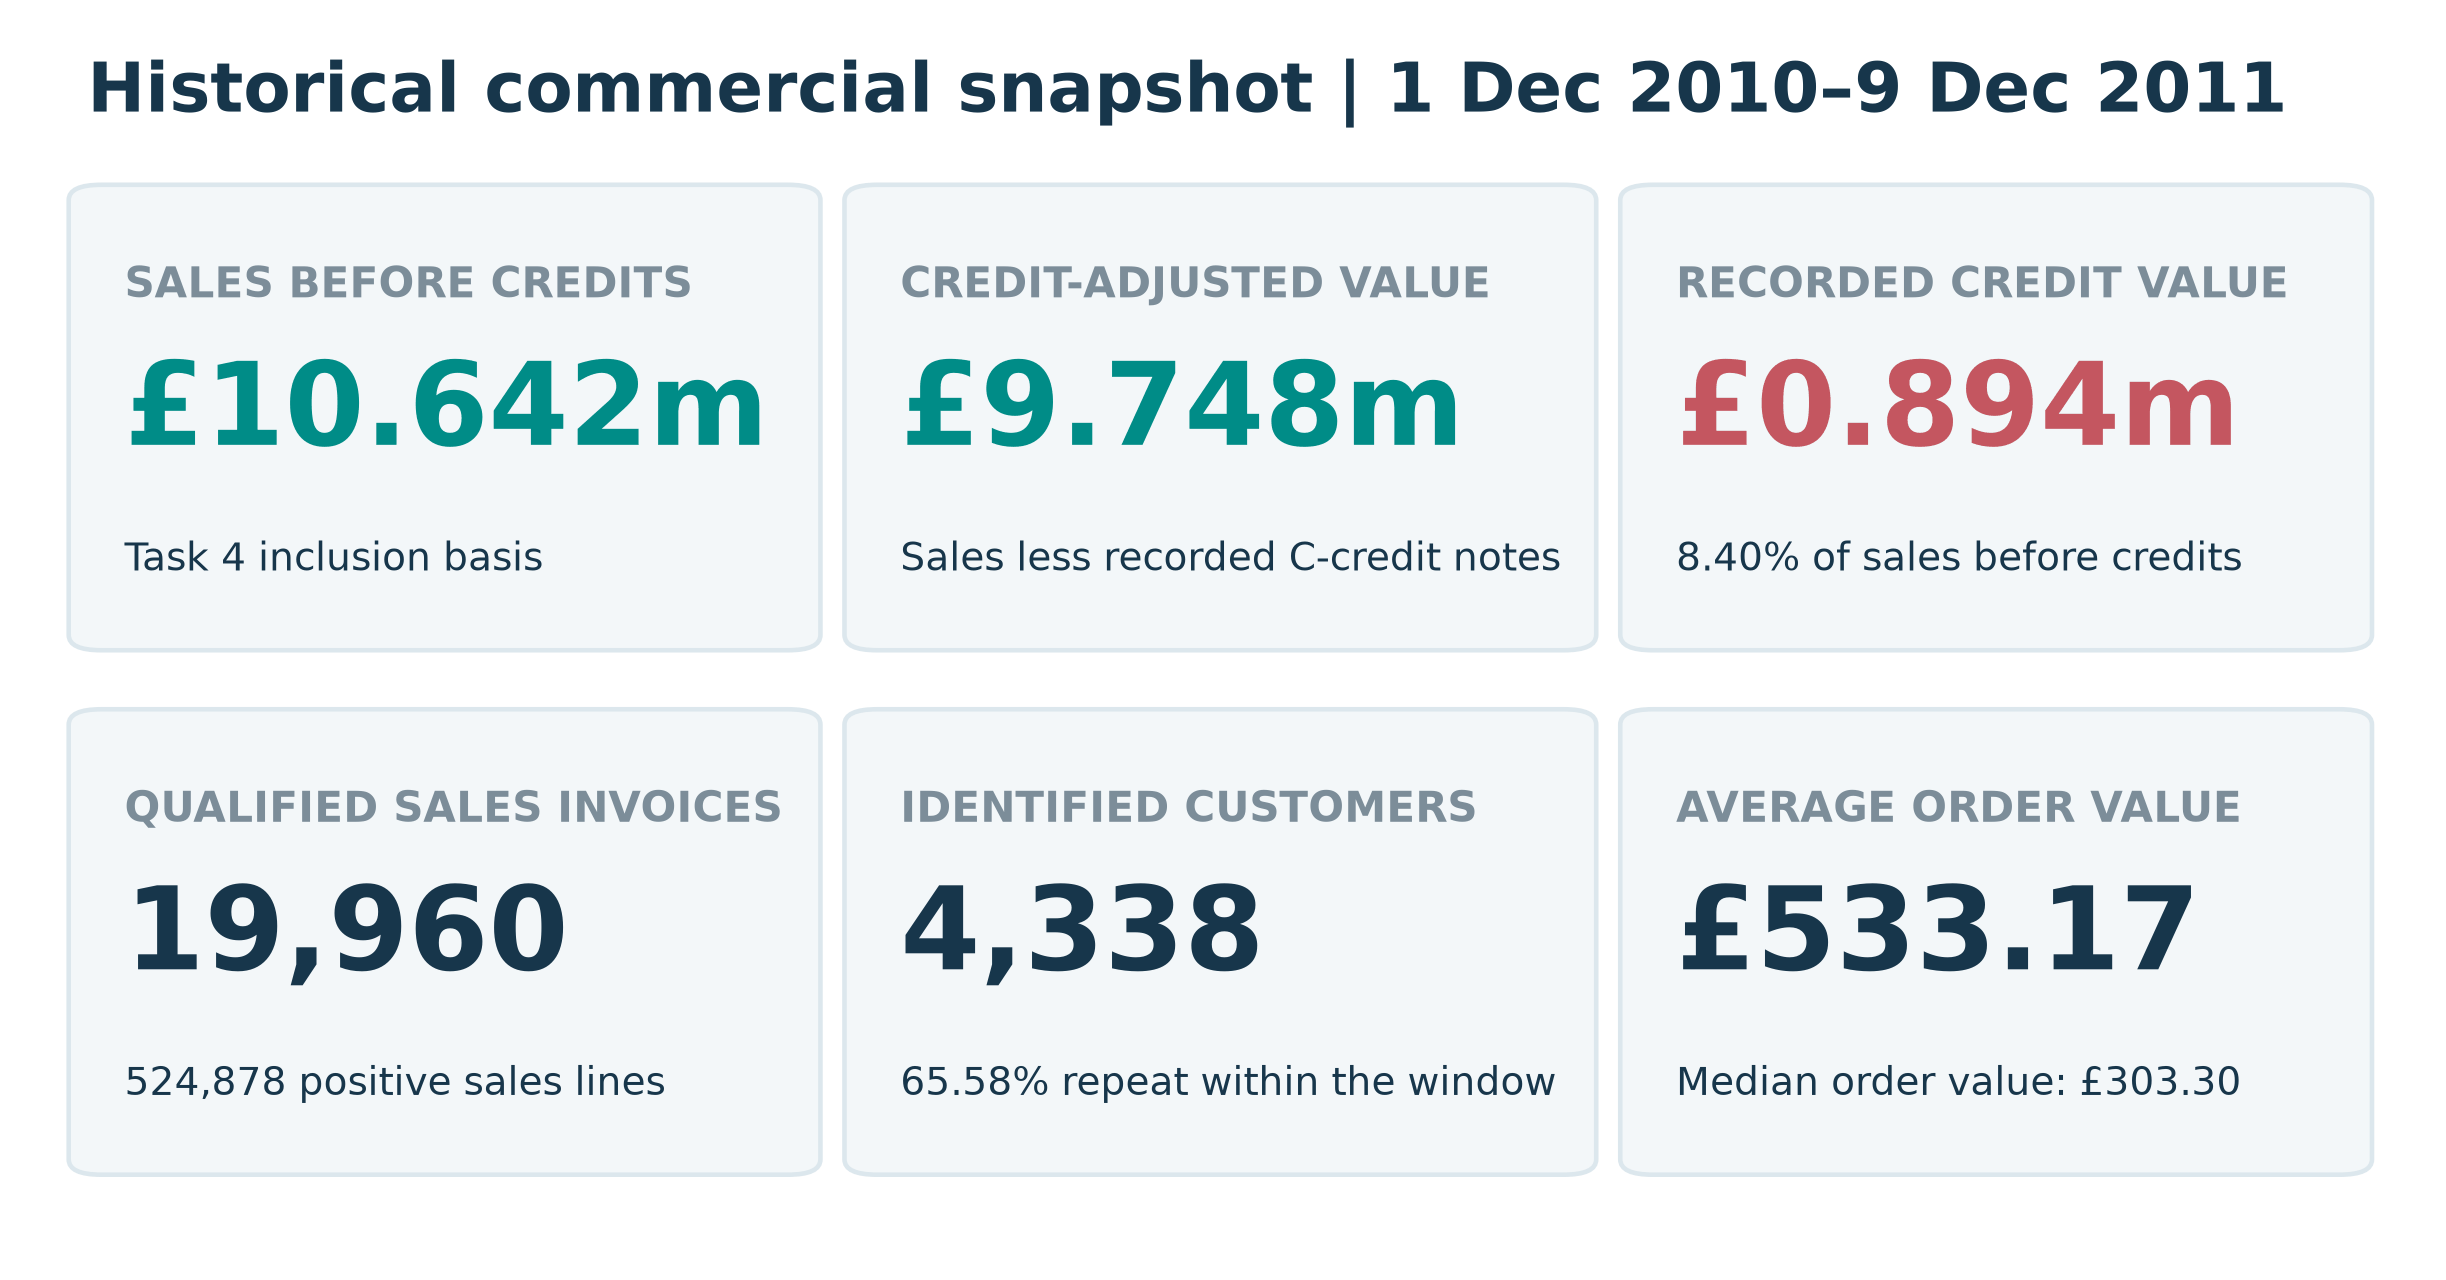

Sales-to-credit-adjusted value reconciliation


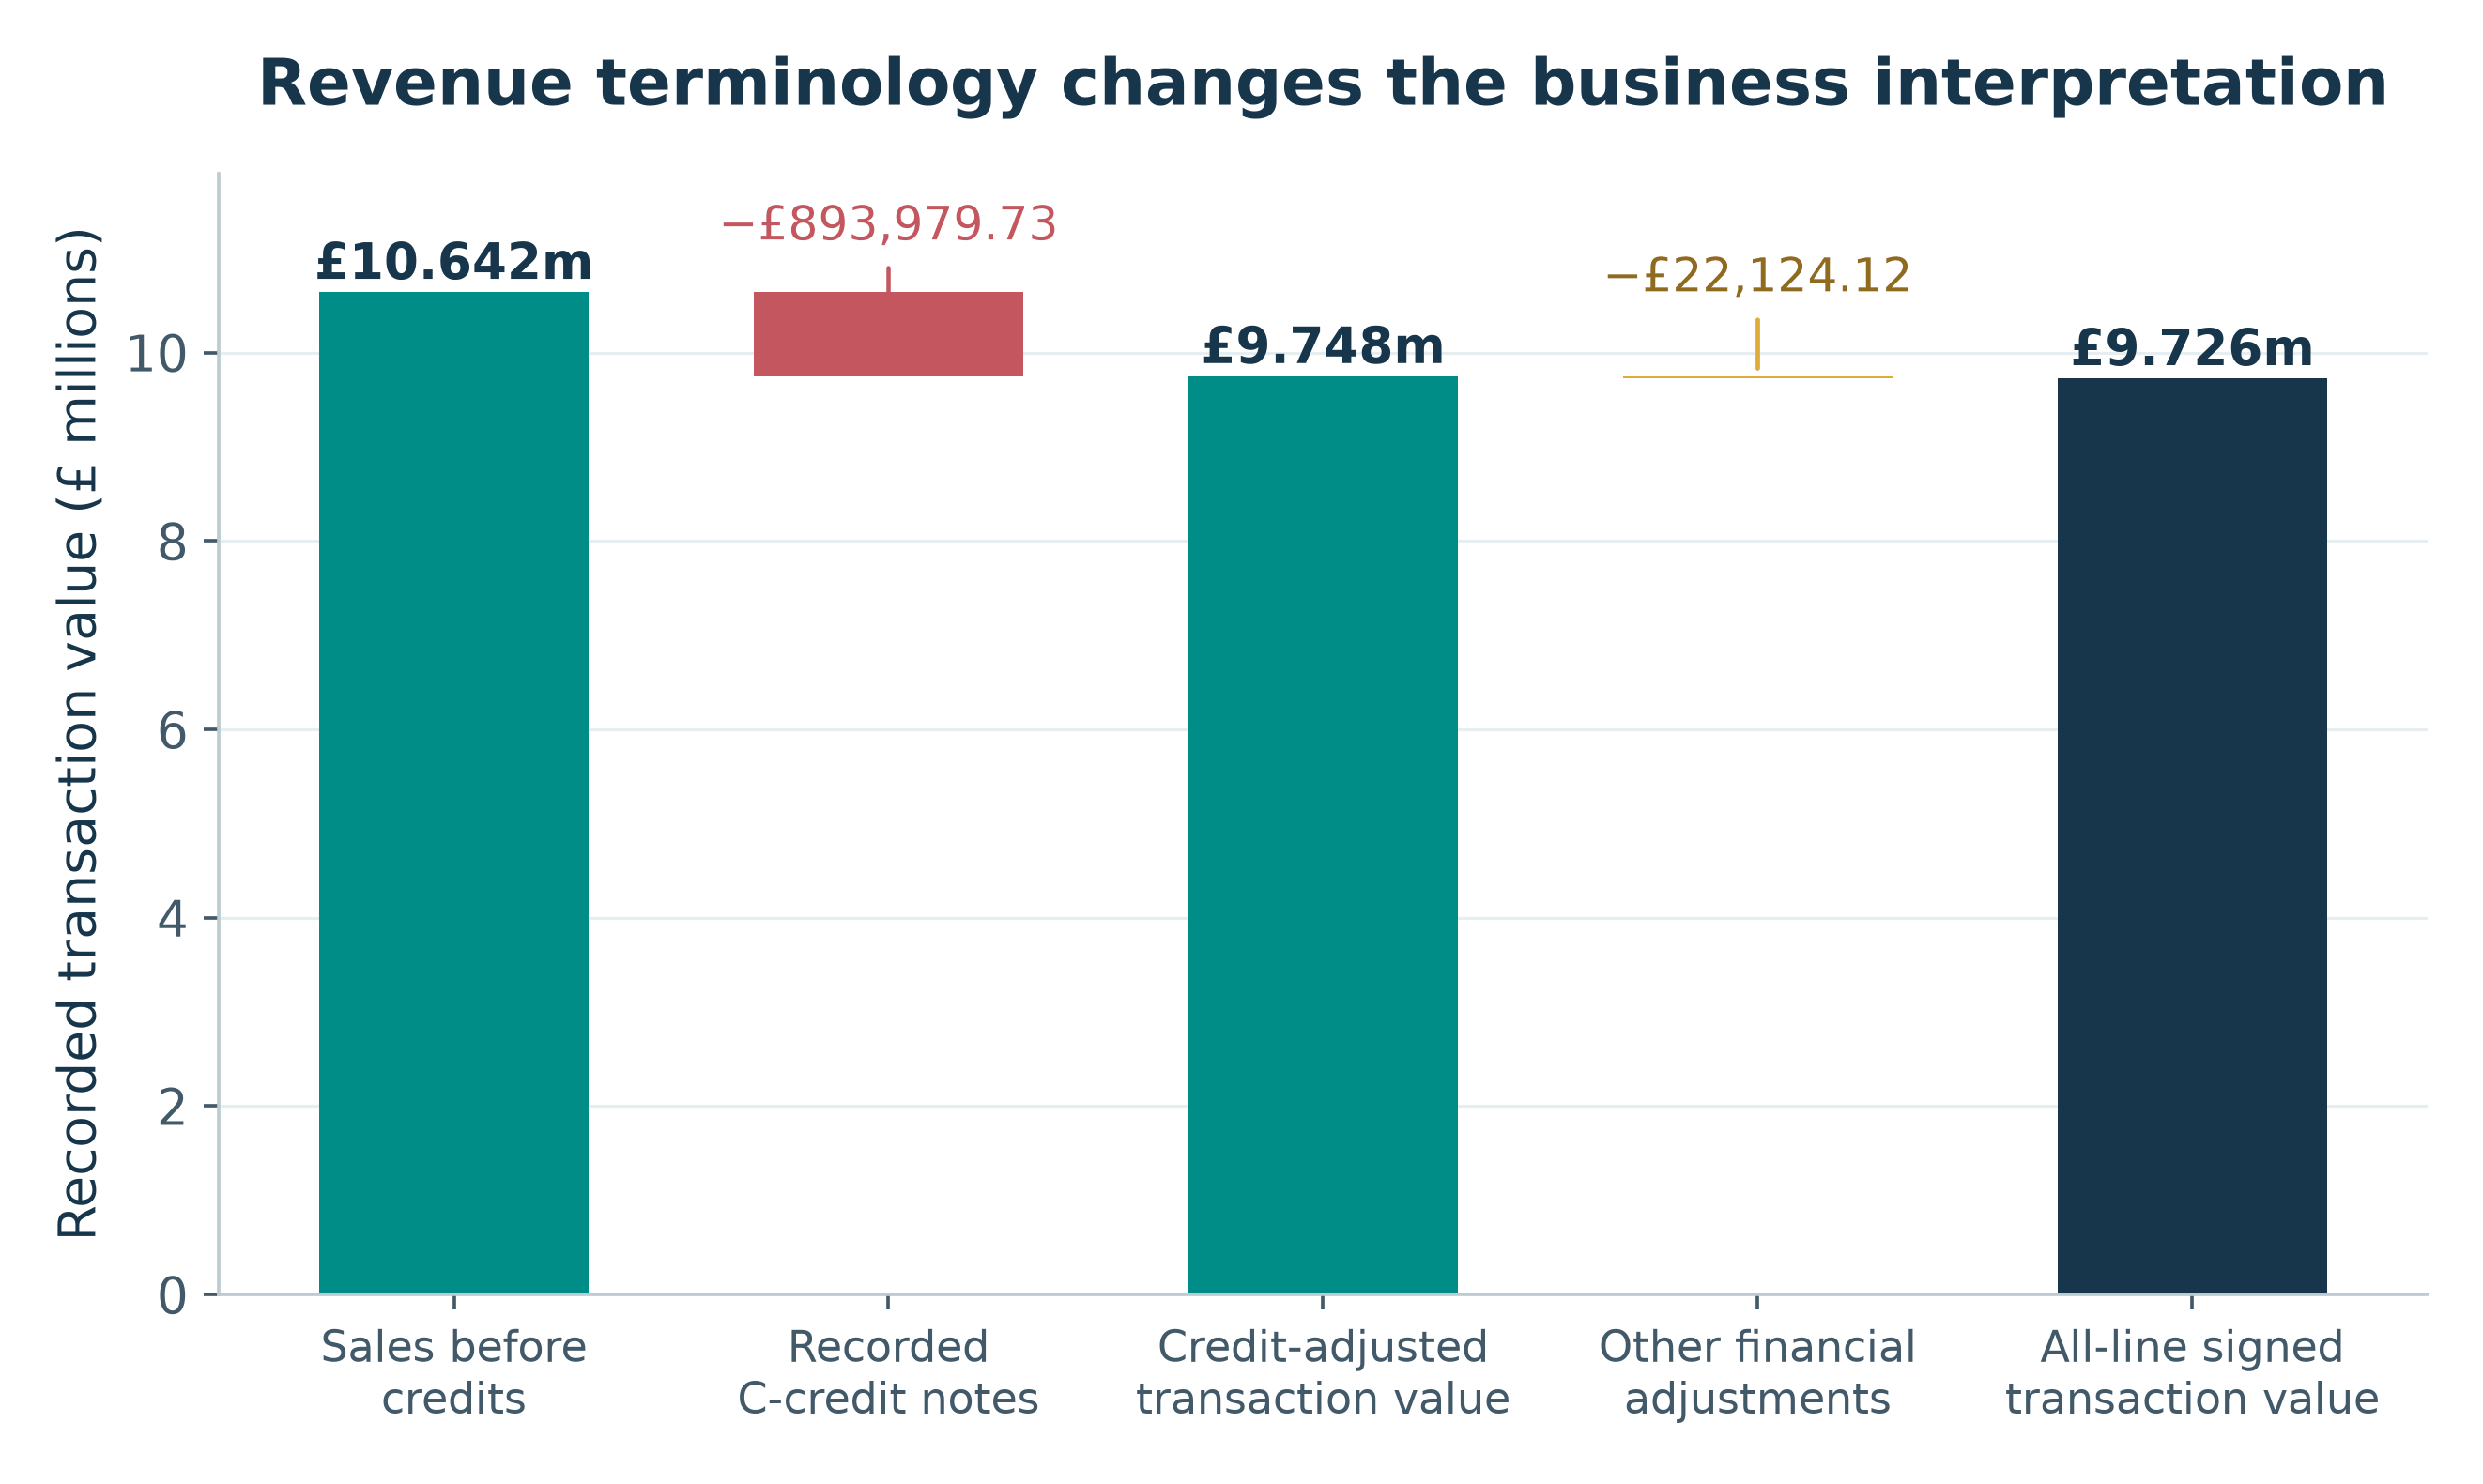

Monthly sales before credits and credit-adjusted value


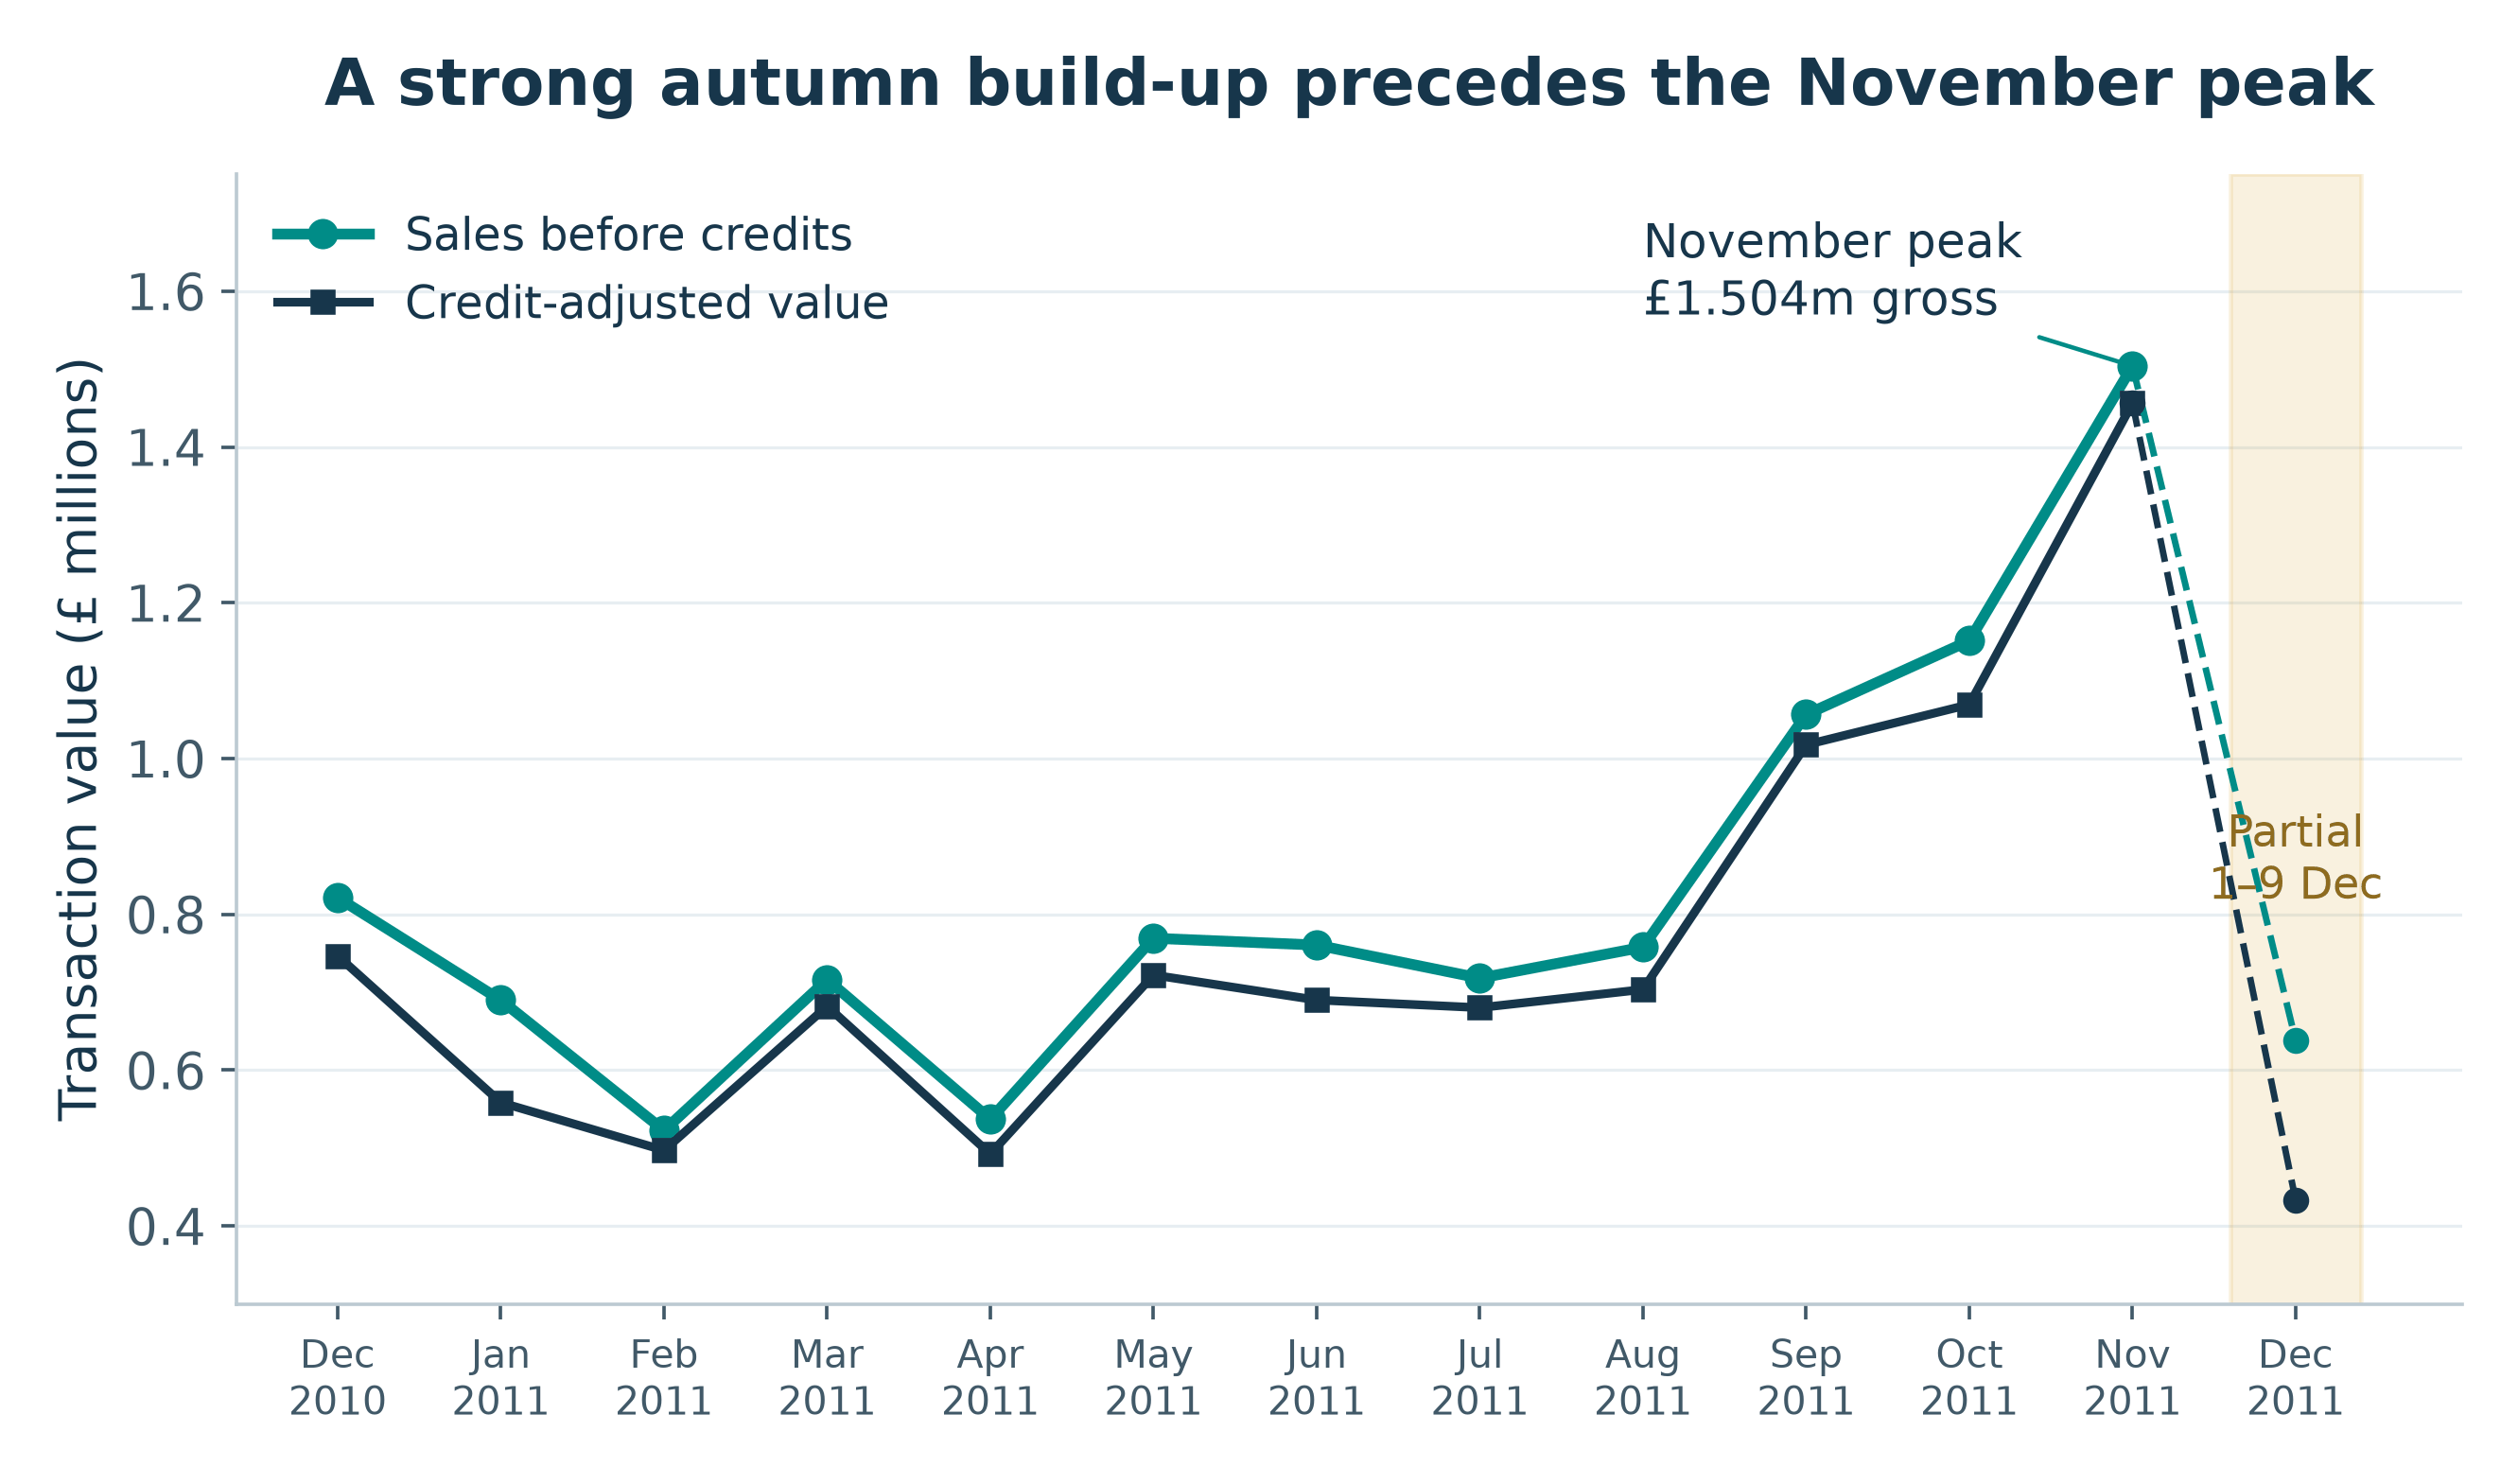

Monthly credit counts, document share and value ratio


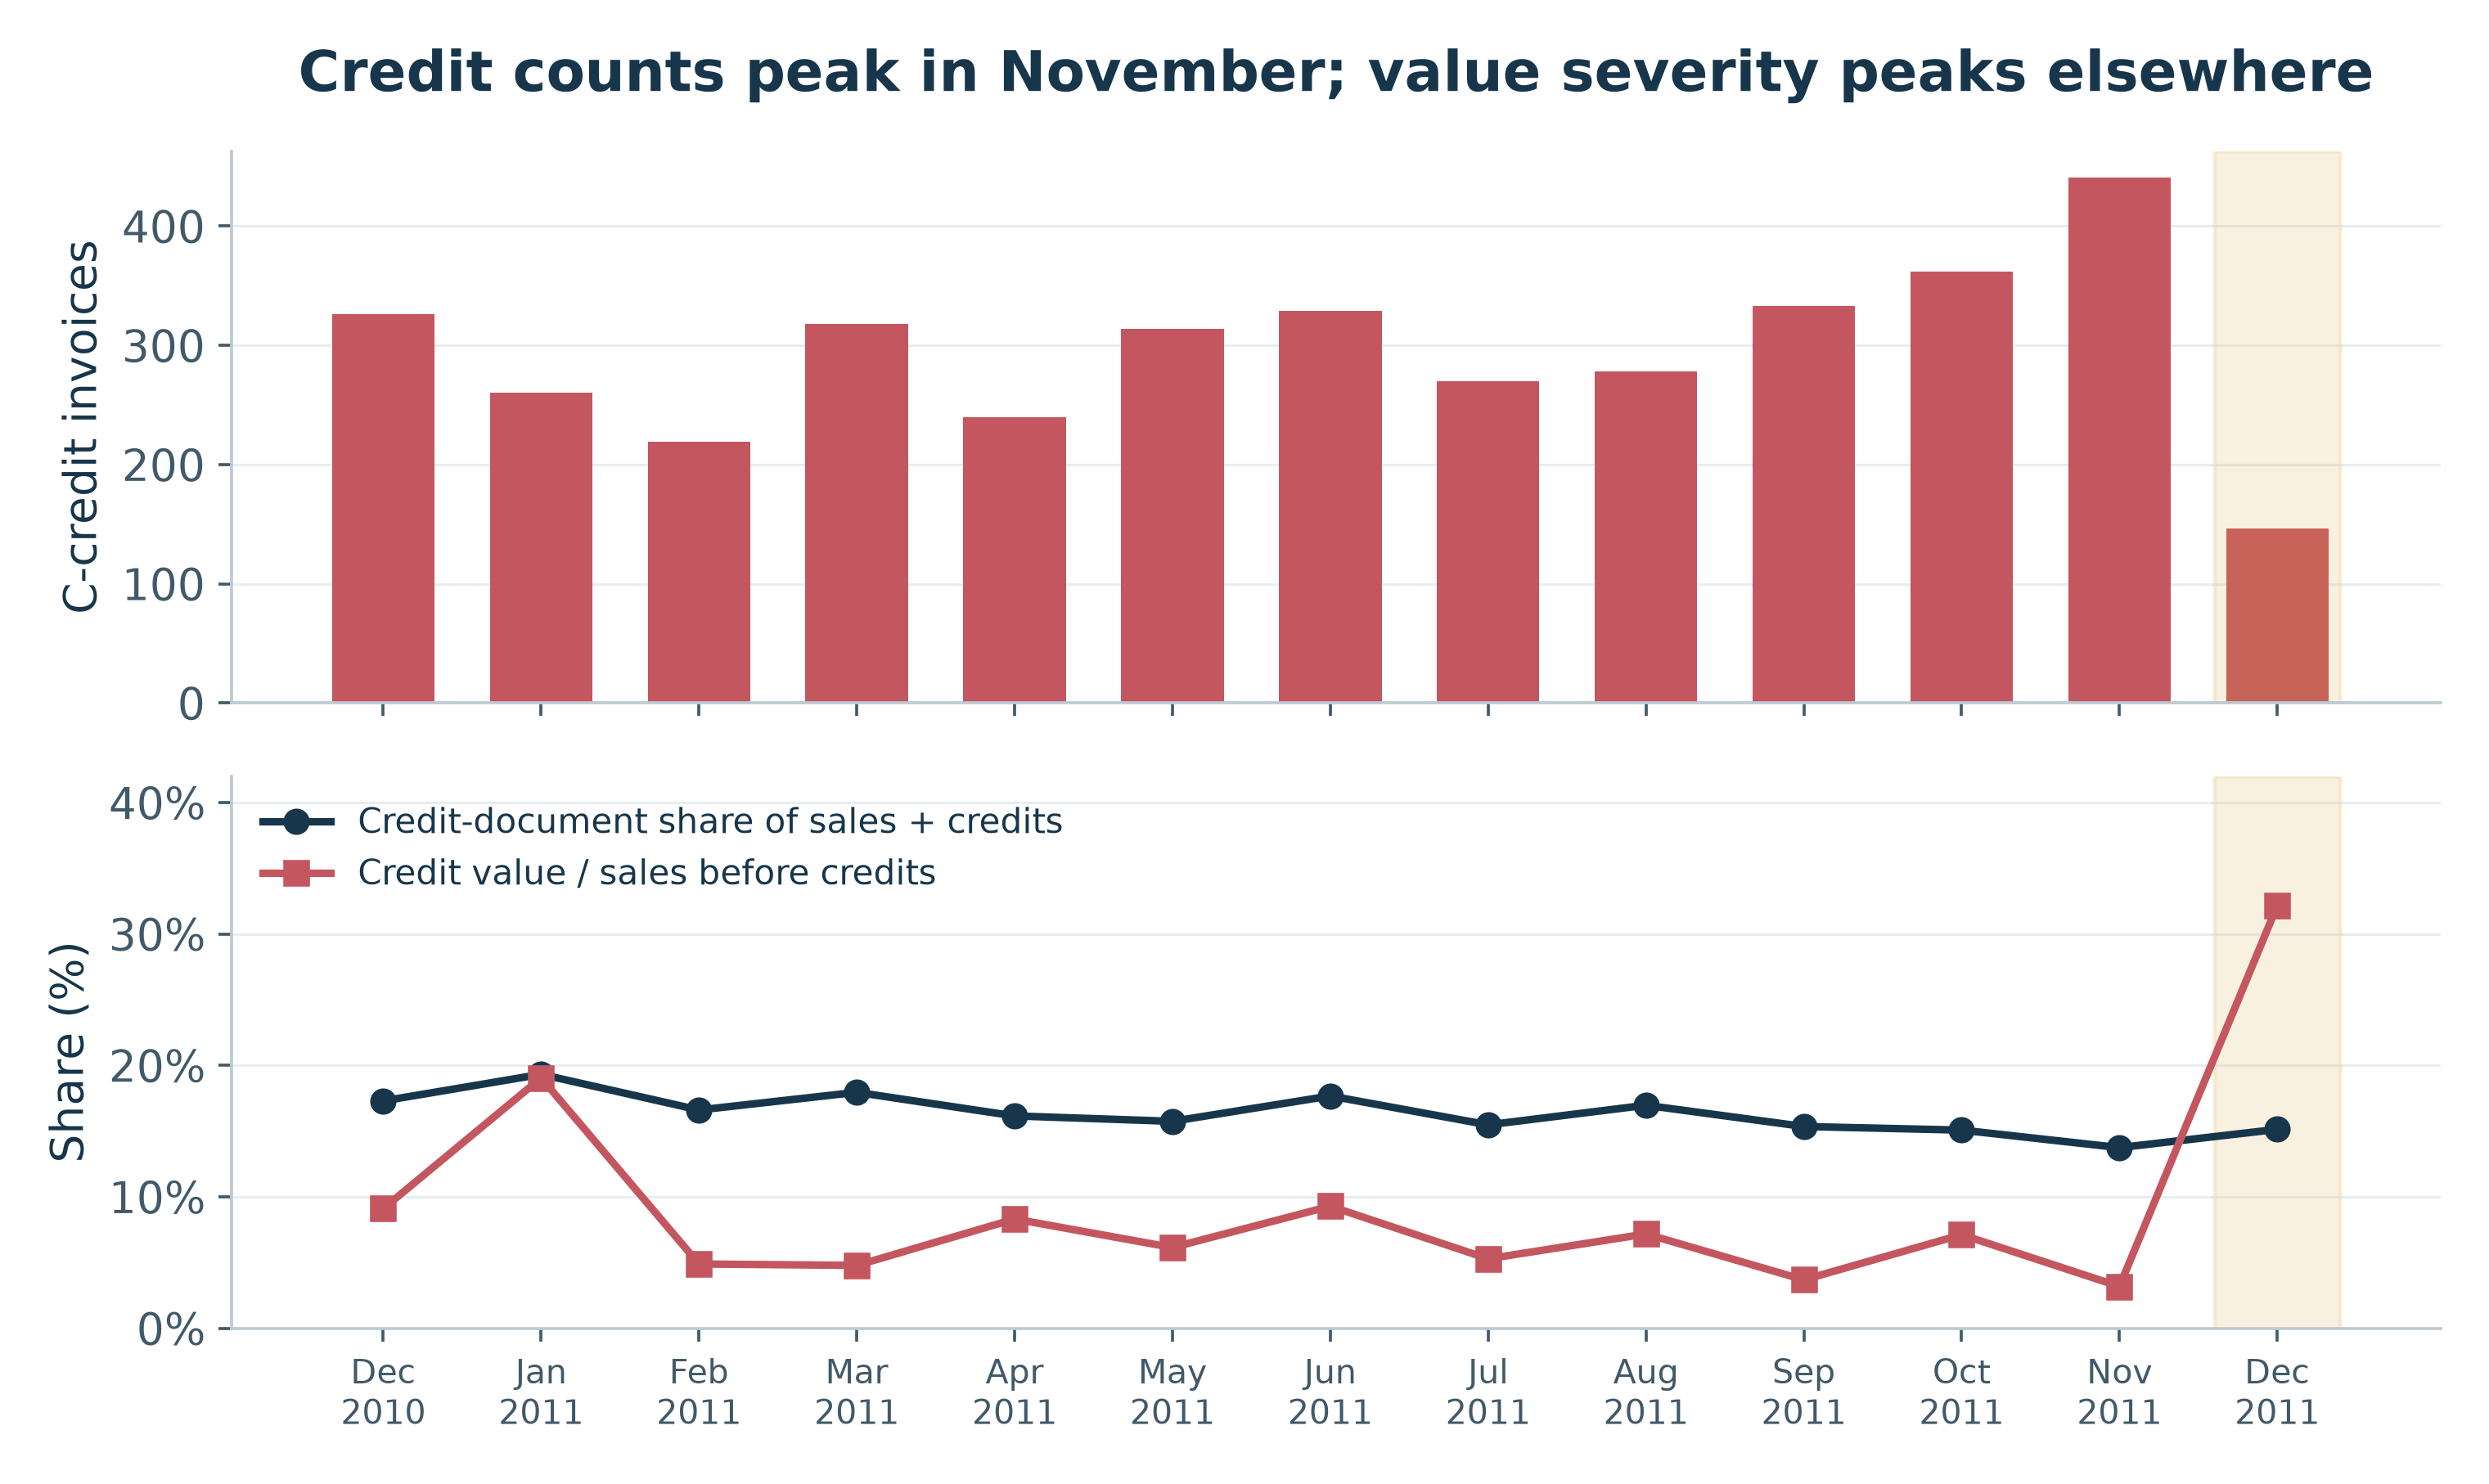

Customer sales concentration on the identified-customer basis


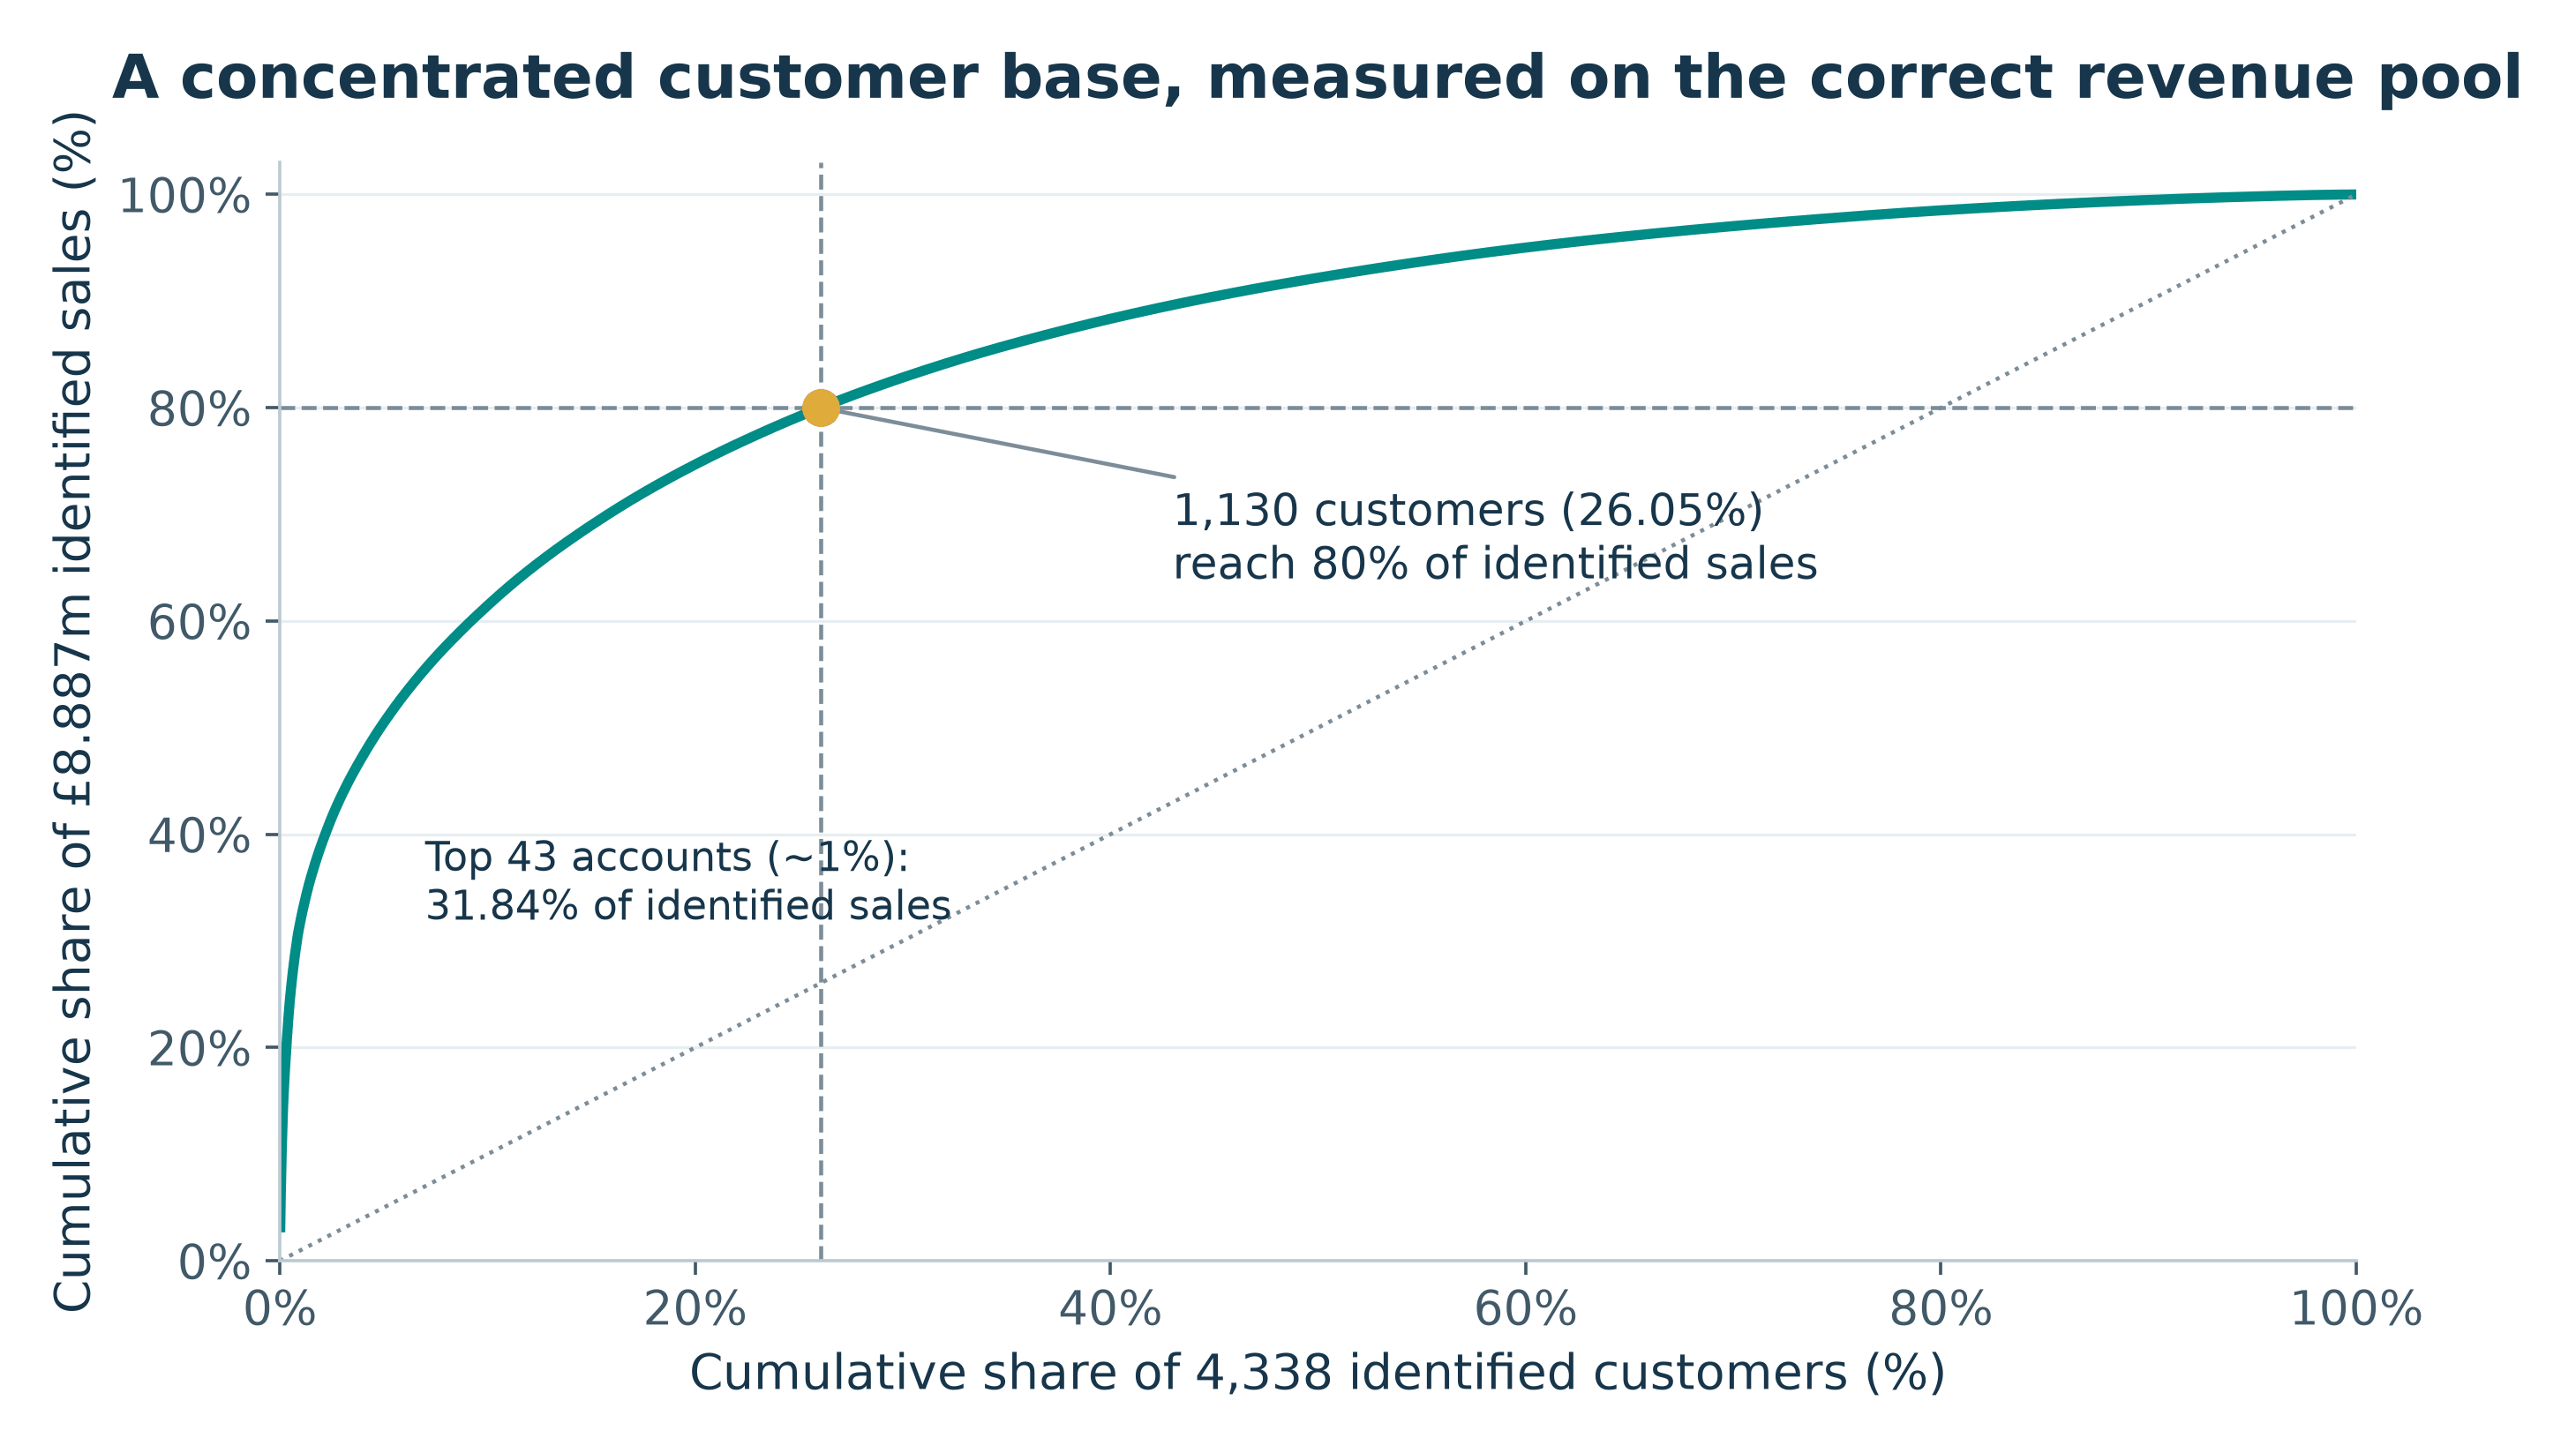

RFM customer counts and identified-sales contribution


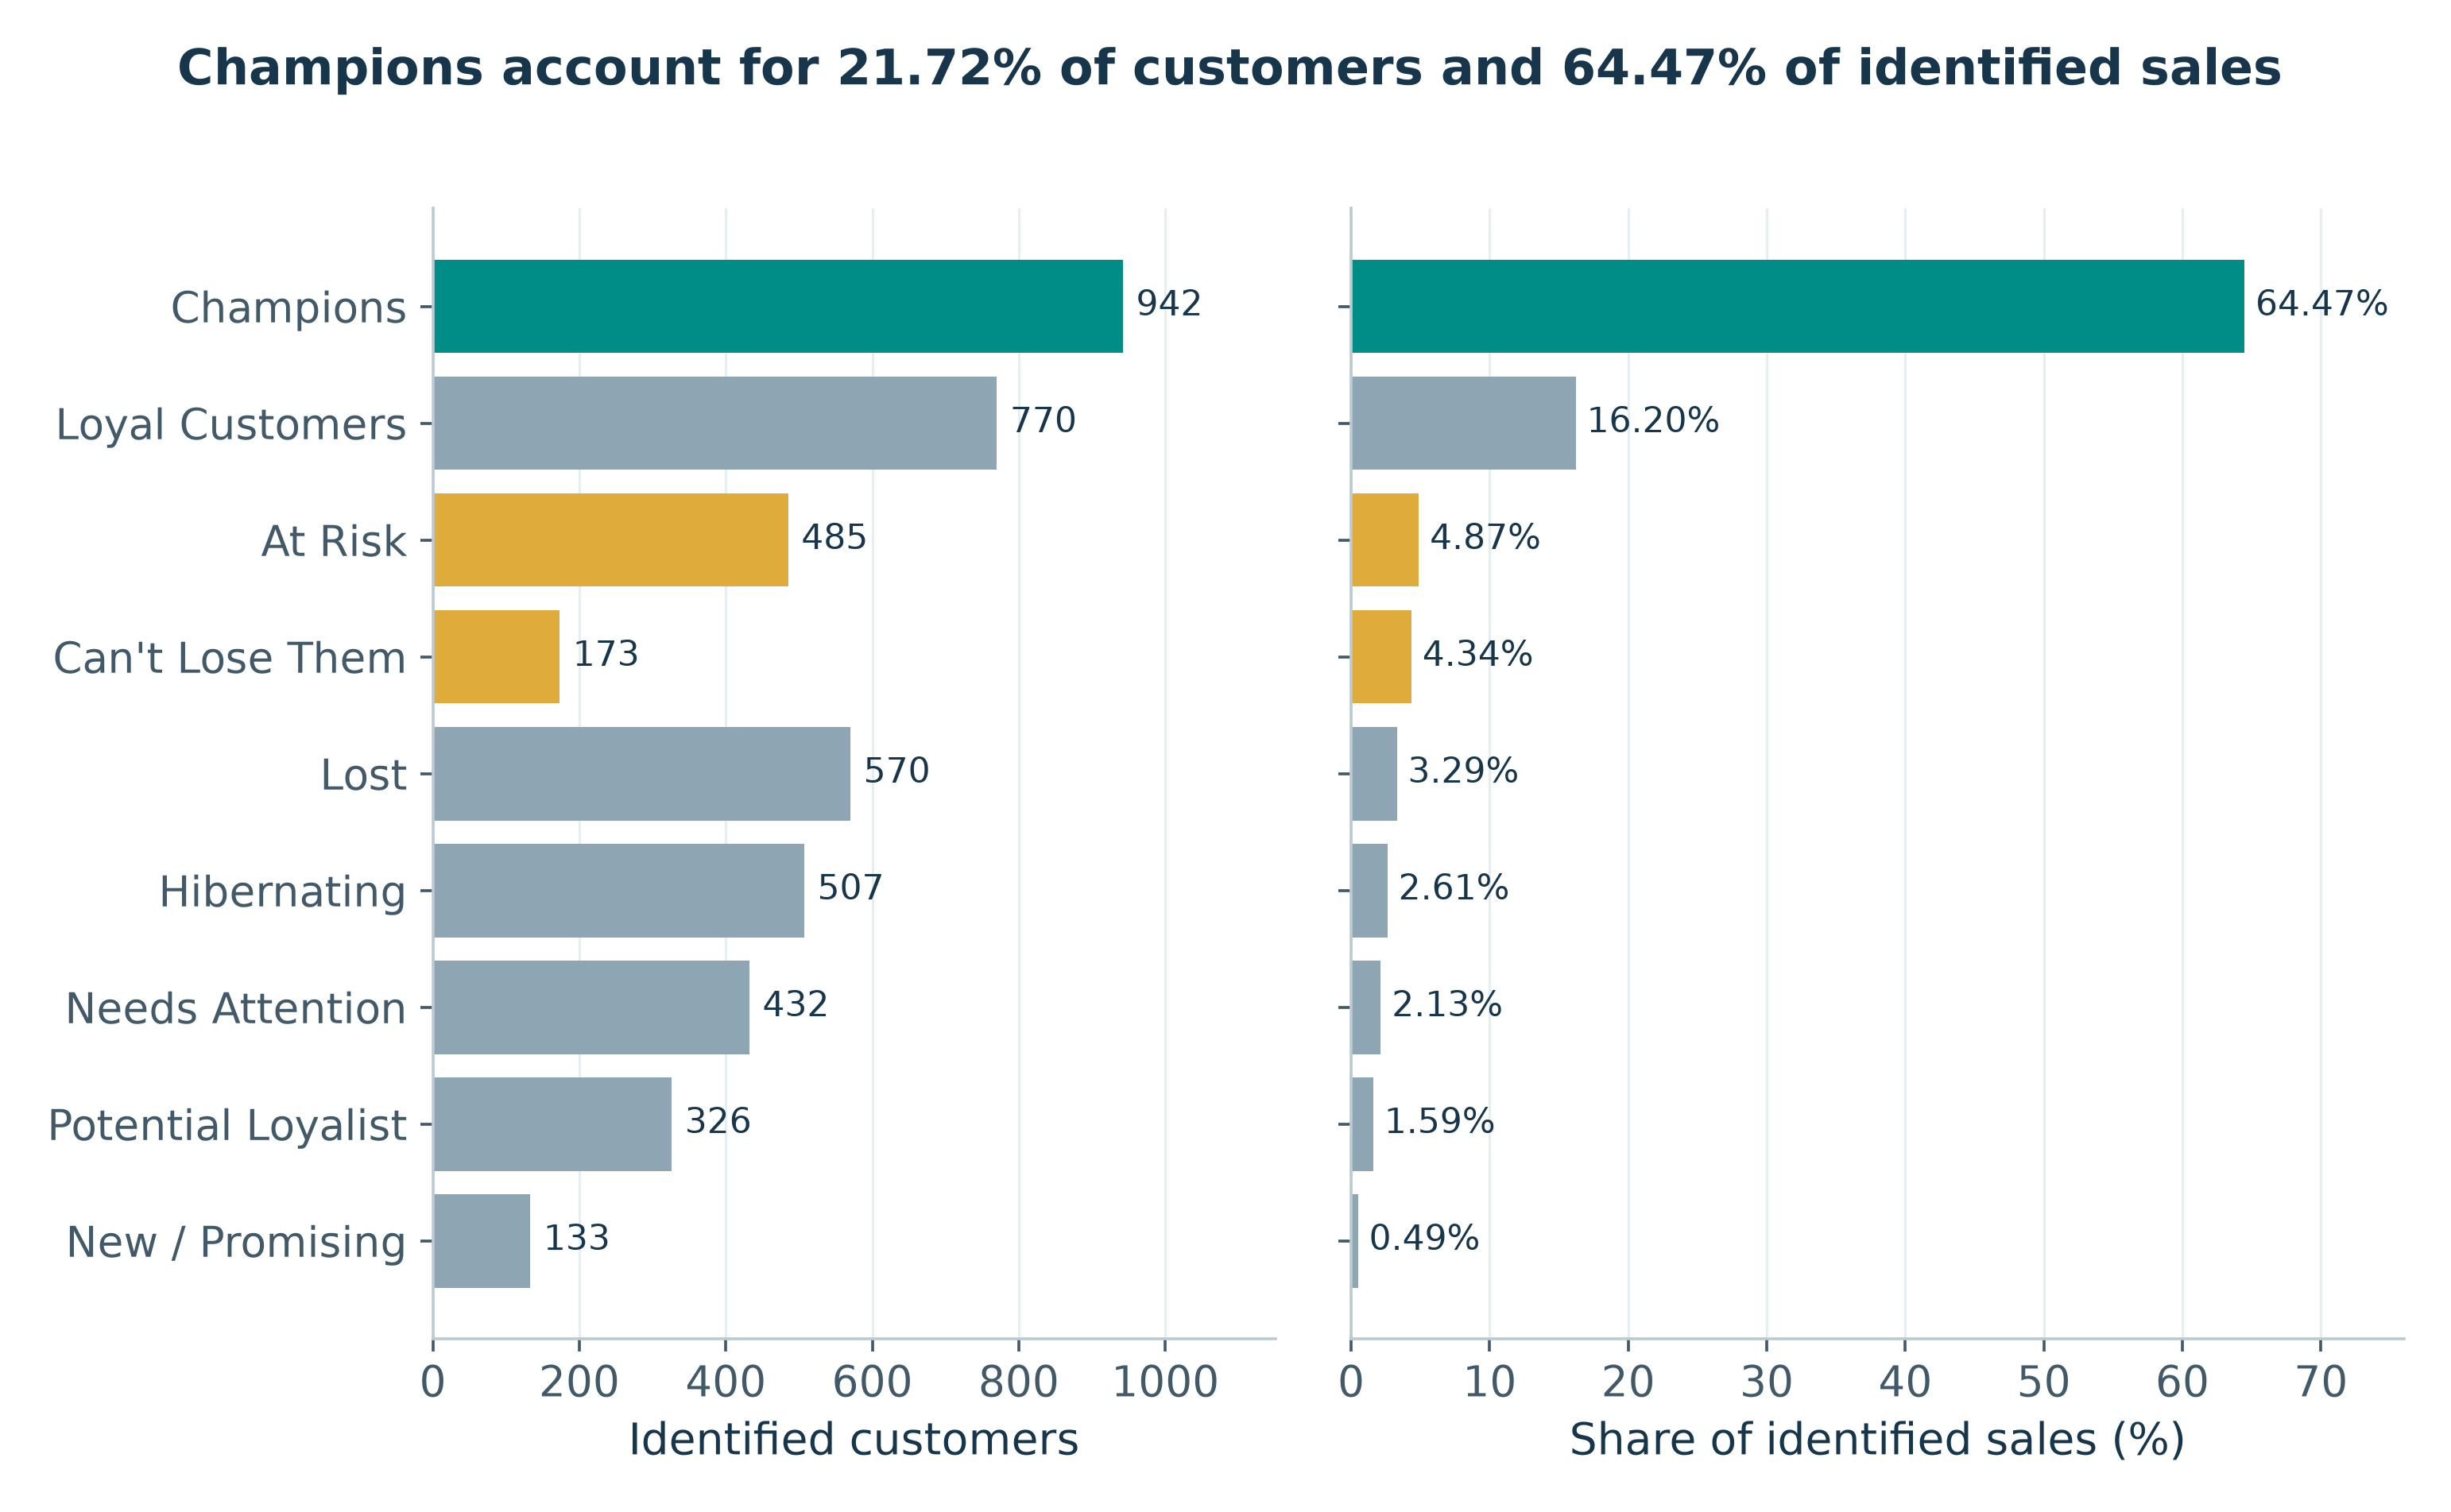

Top merchandise products: gross sales versus credit-adjusted value


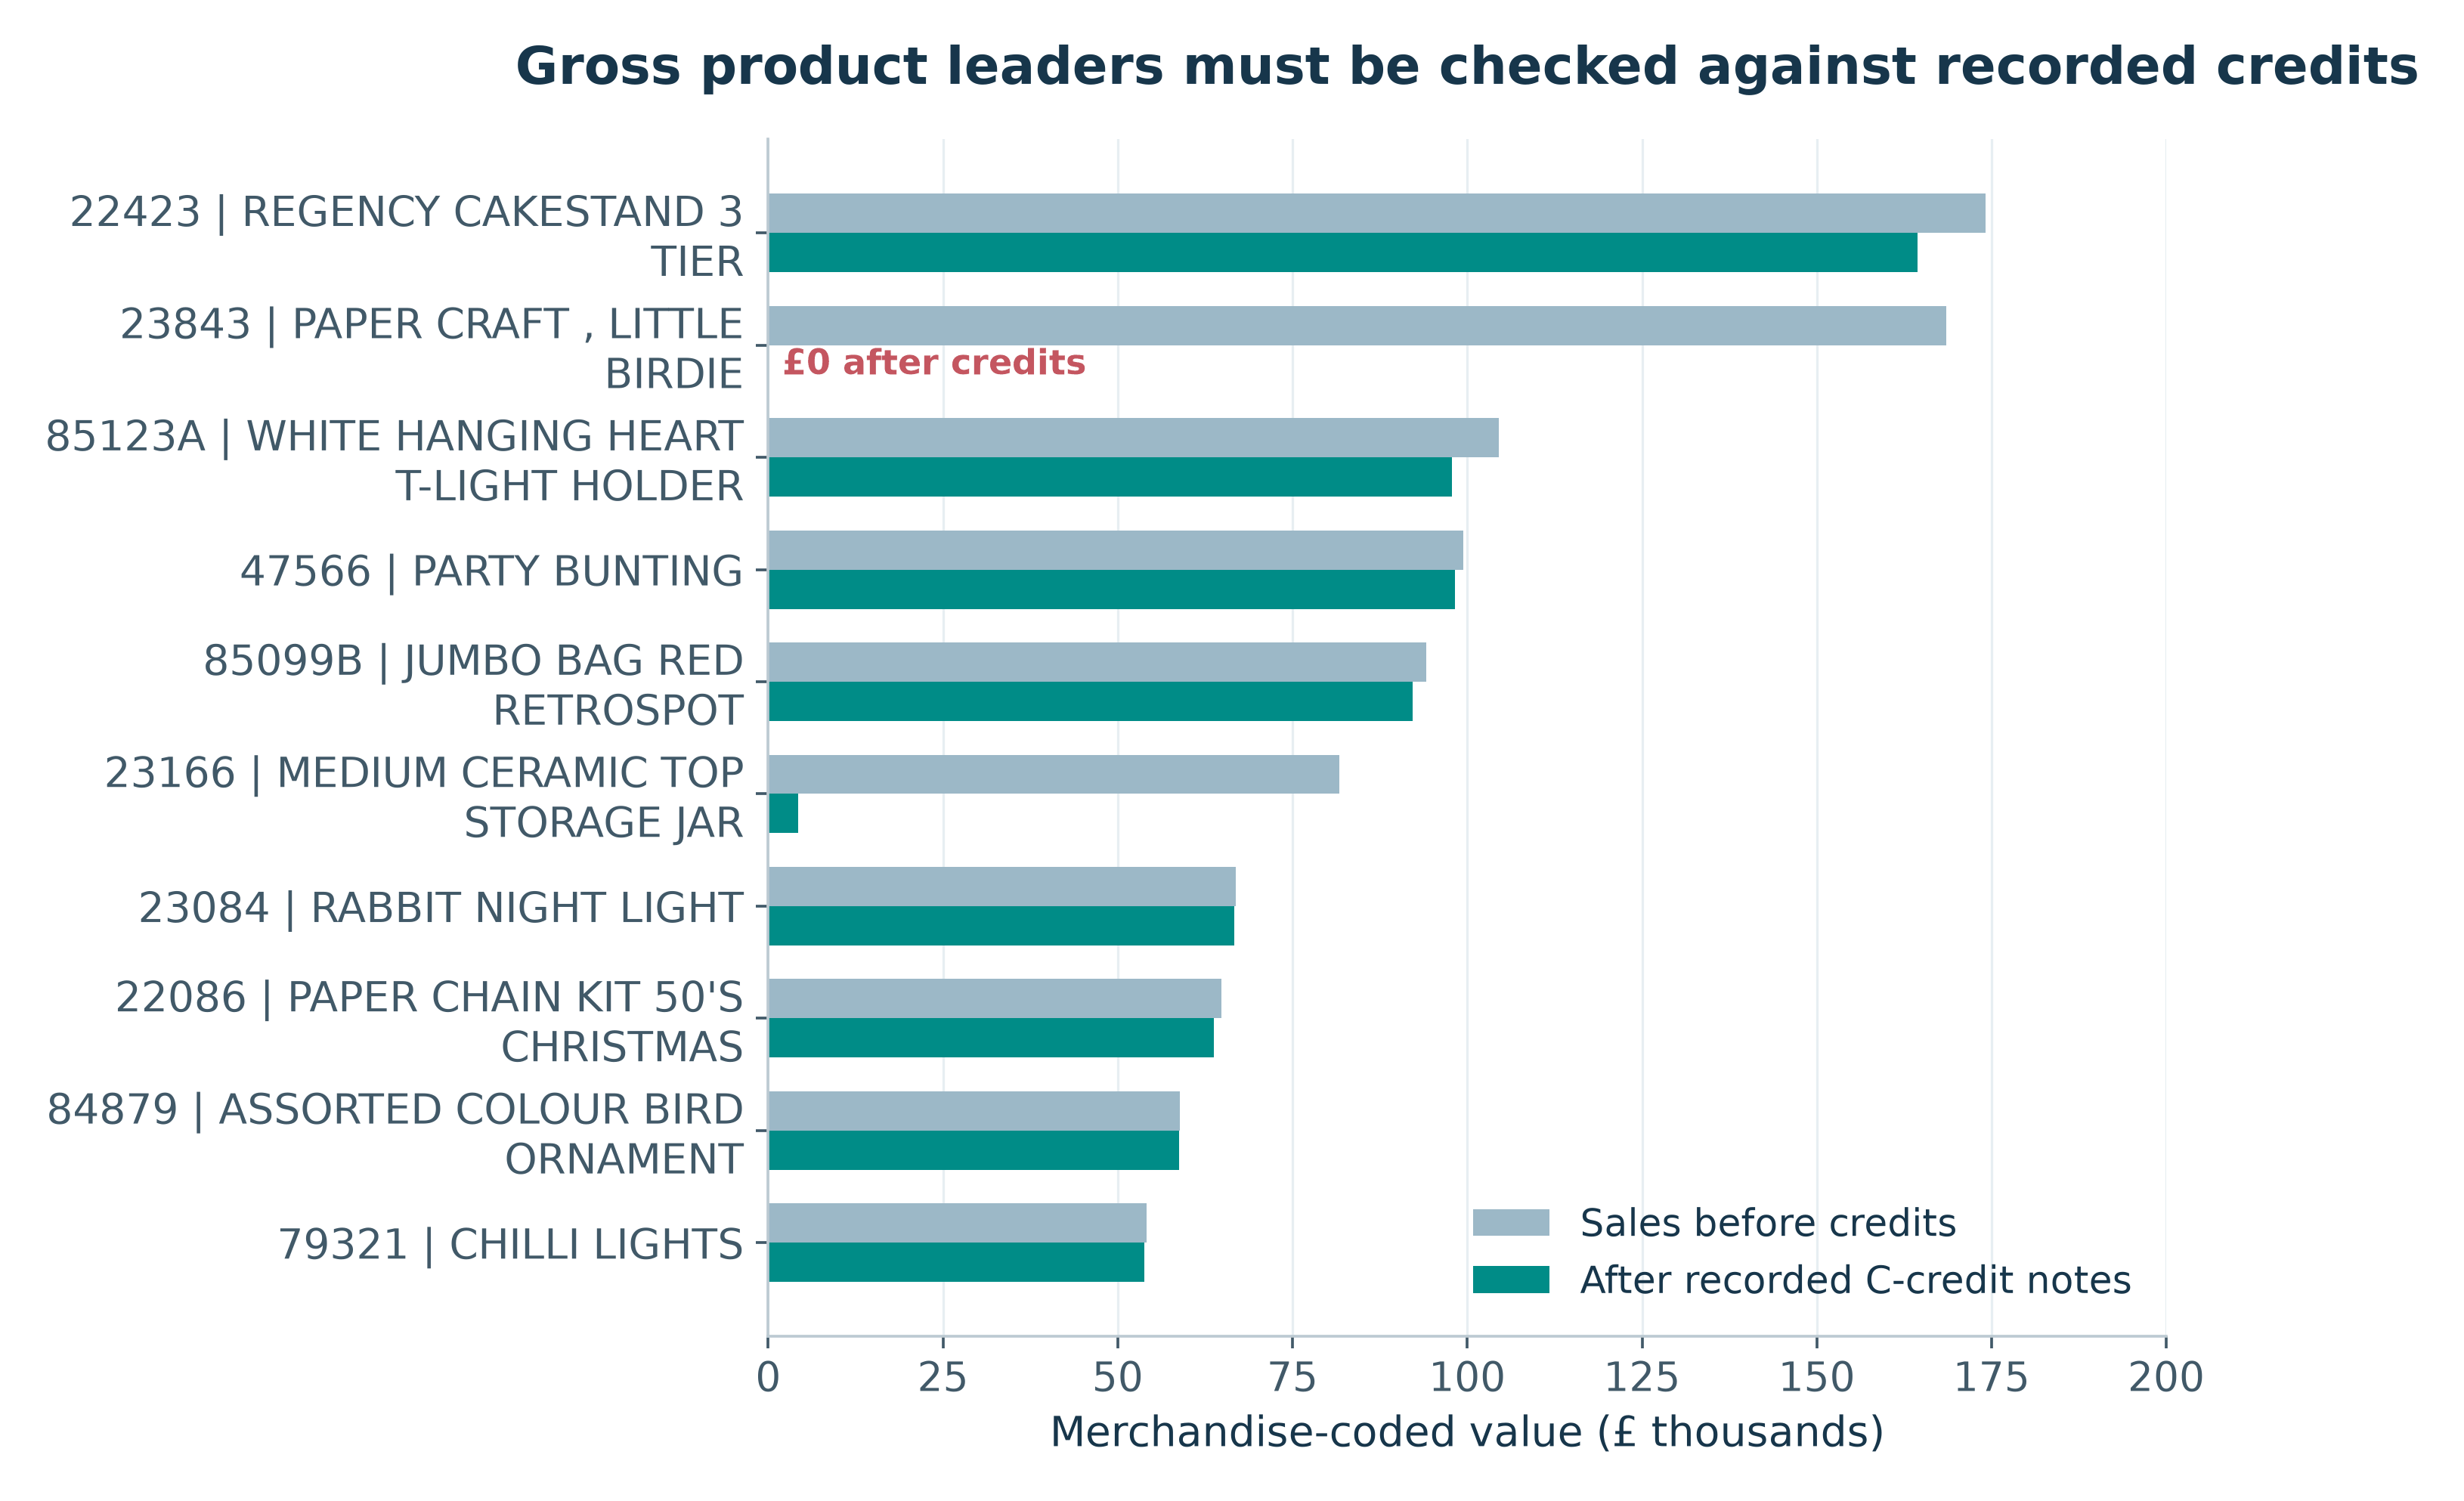

Top ten non-UK country sales


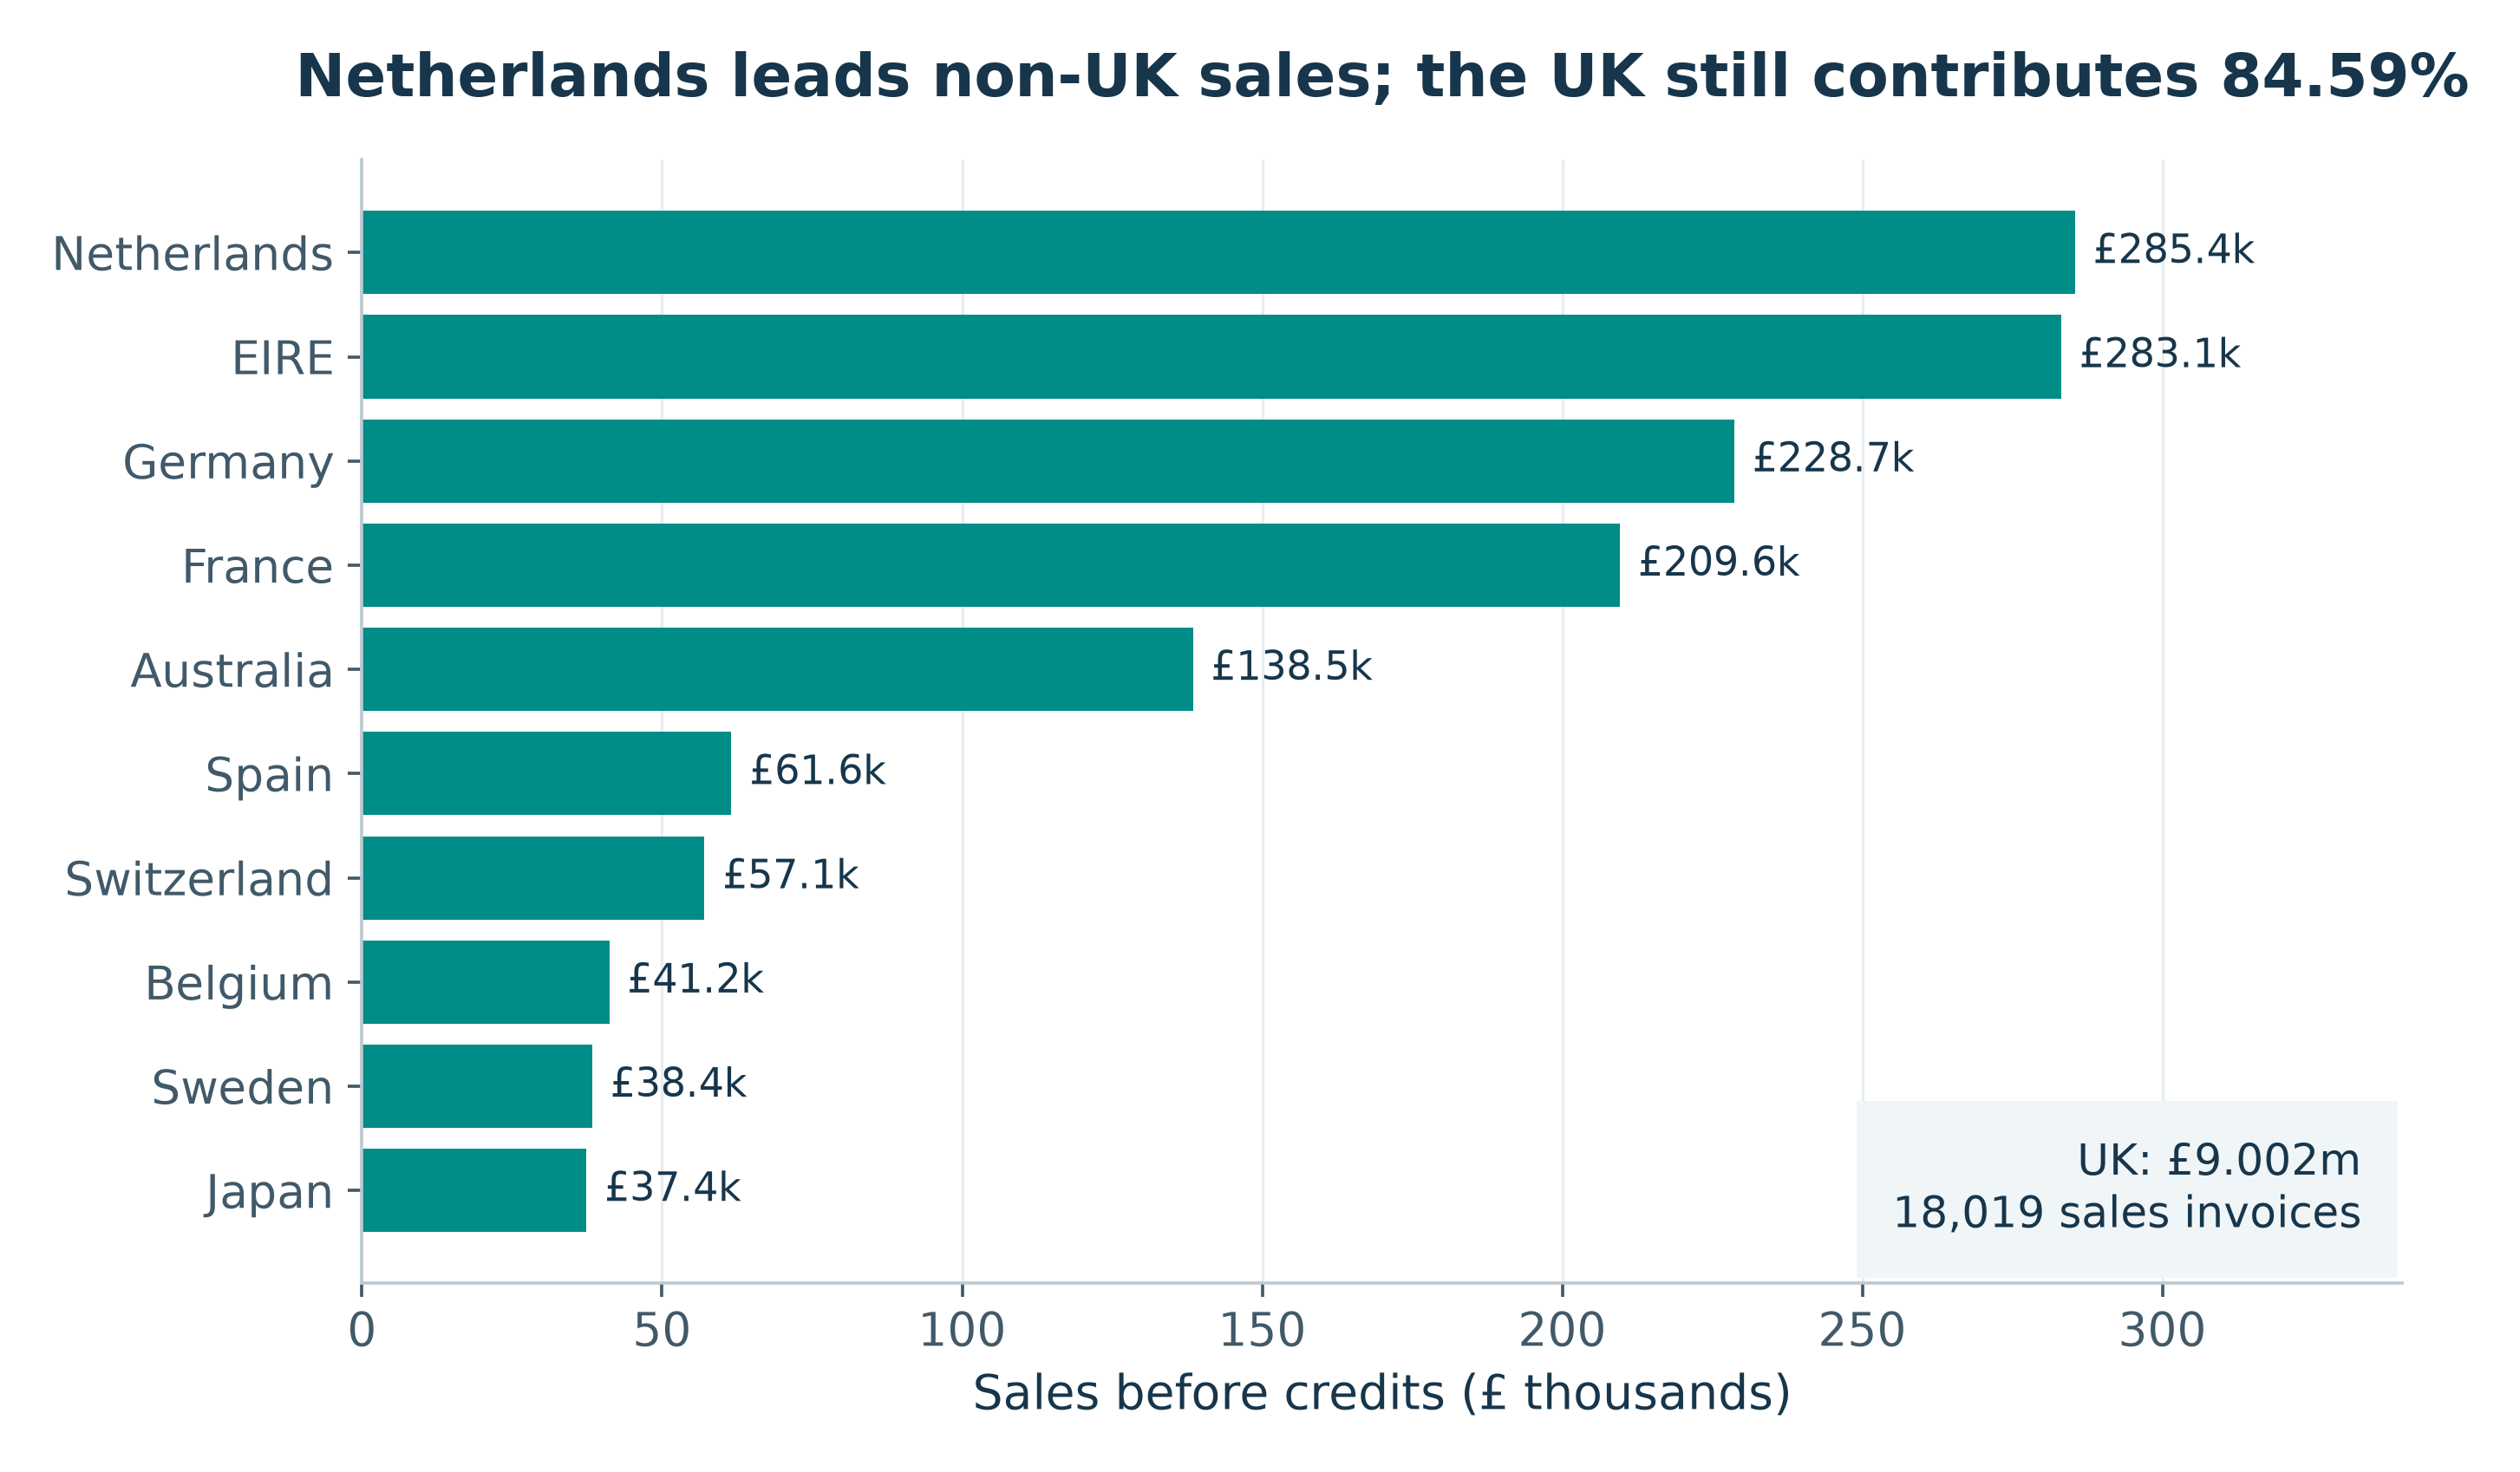

Invoice-value histogram with mean and median


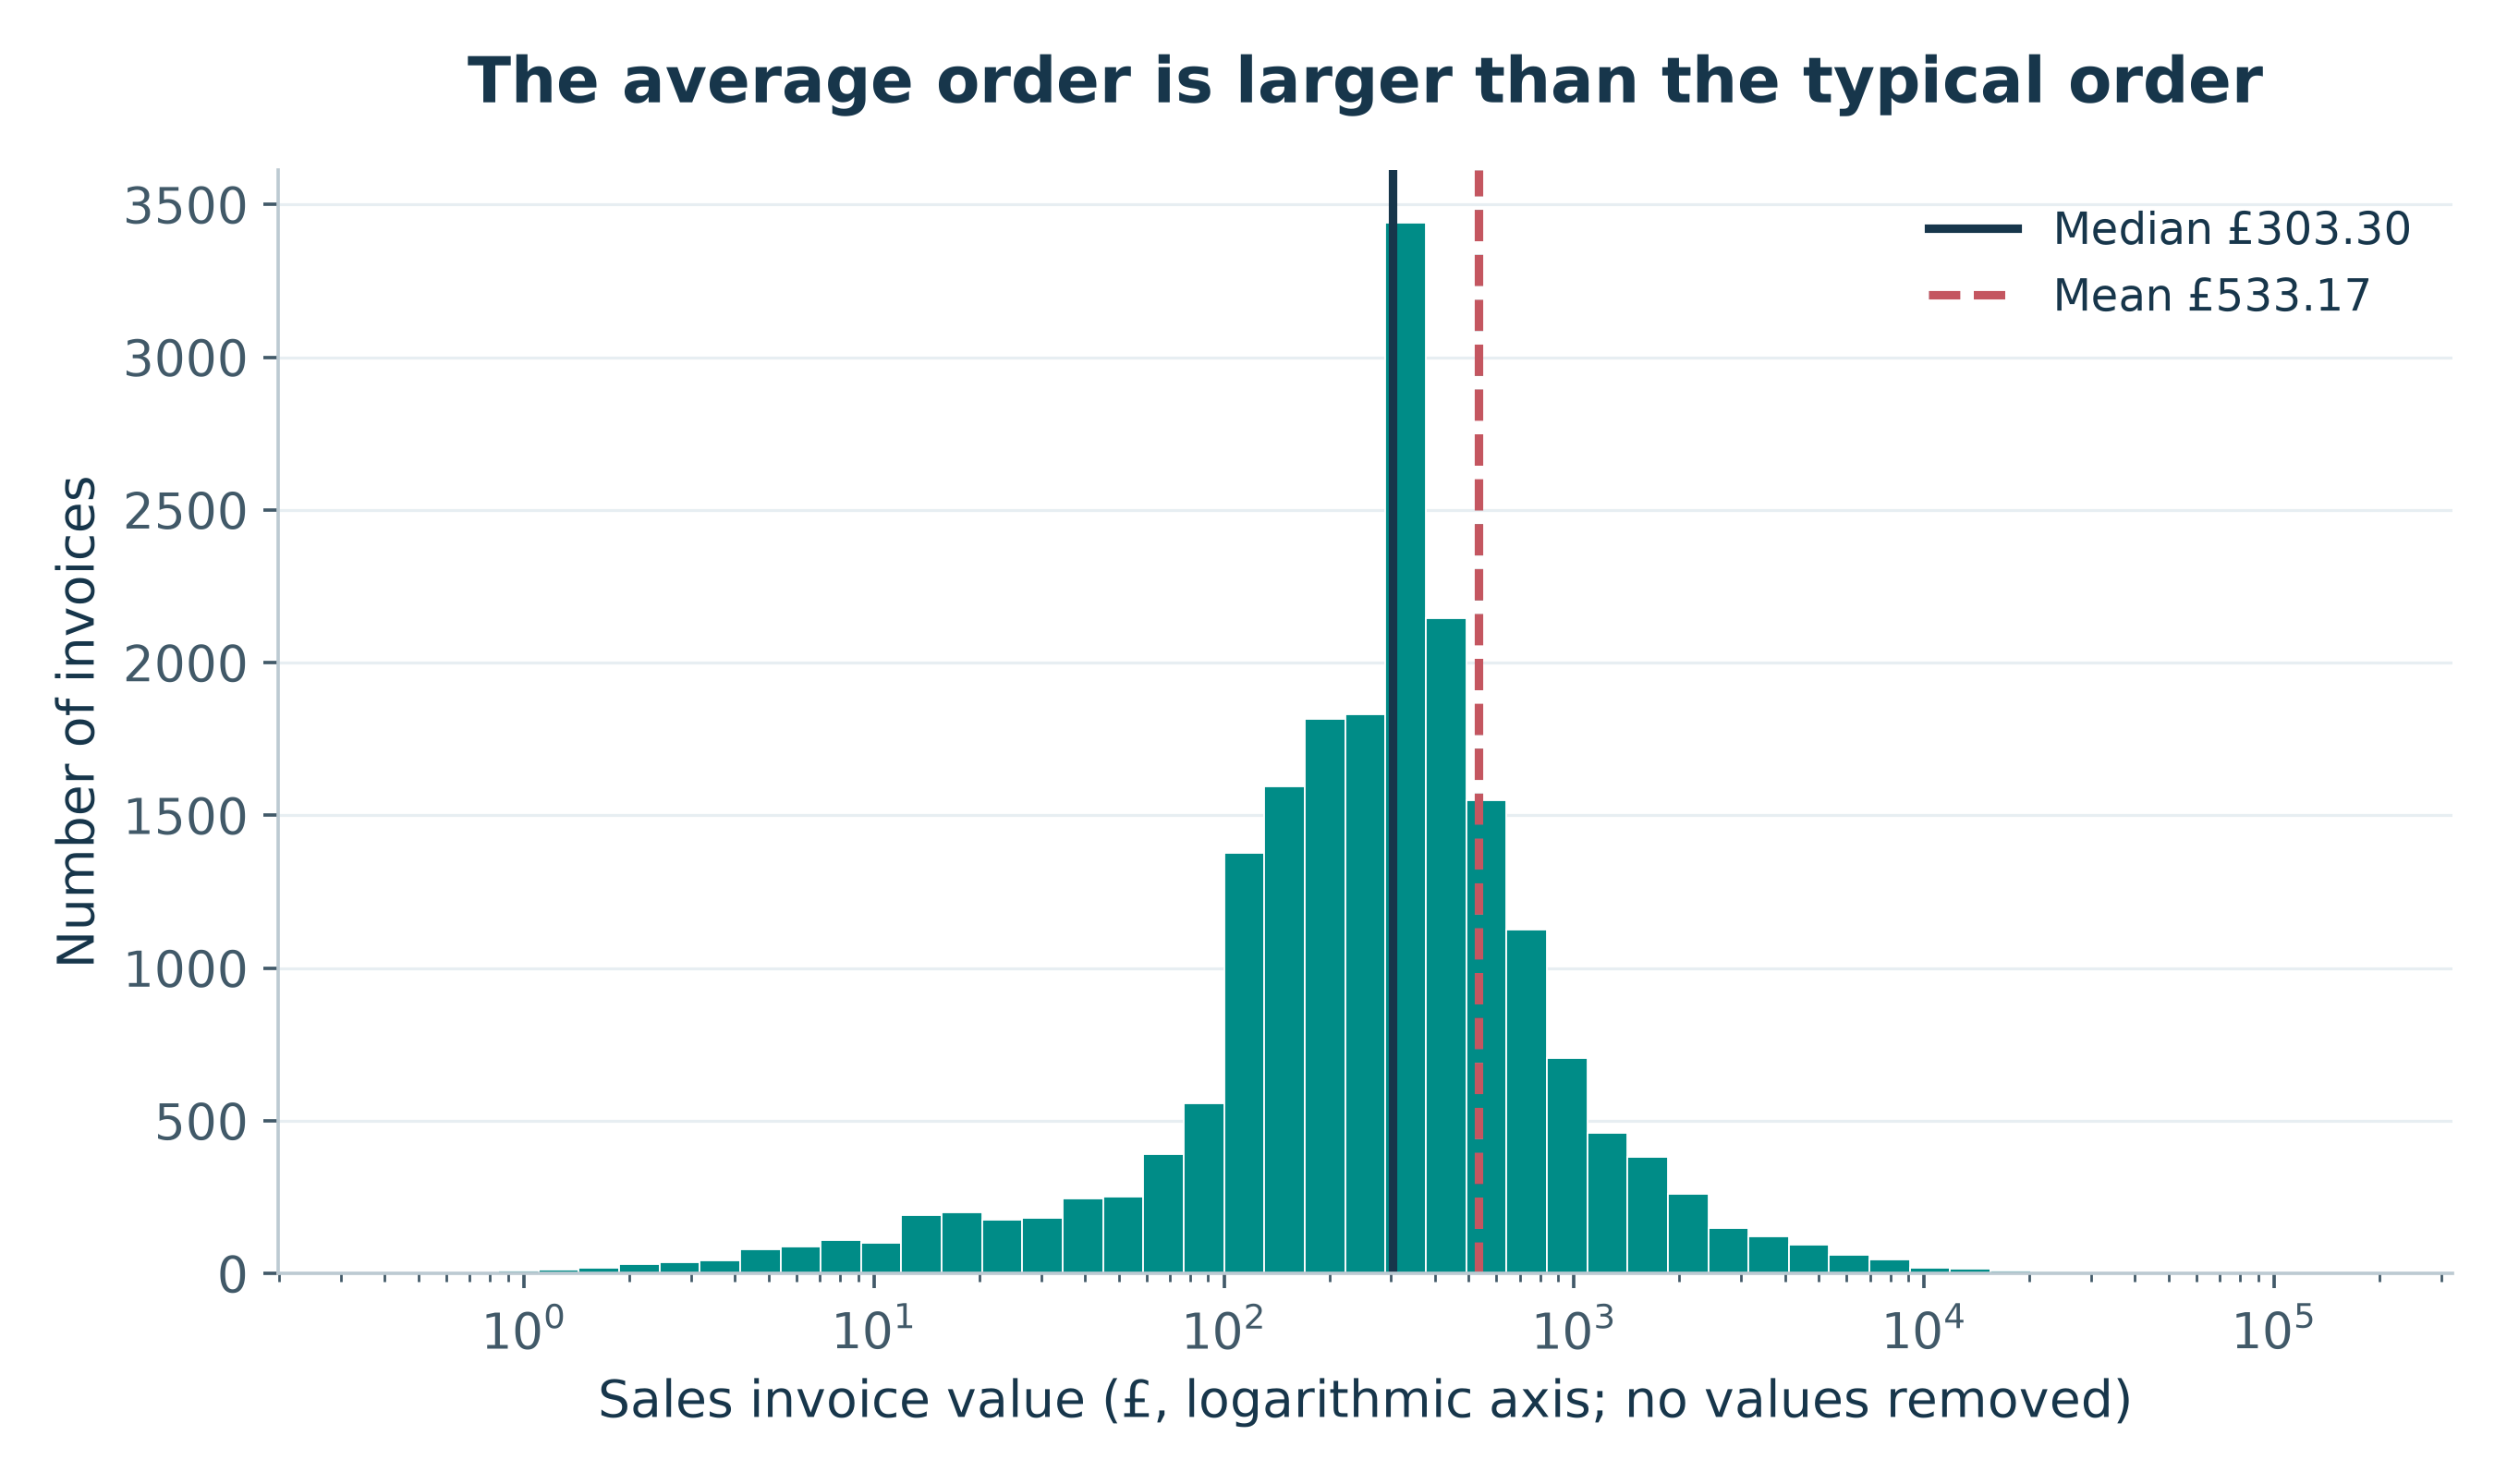

Invoice value versus sales-line count scatter plot


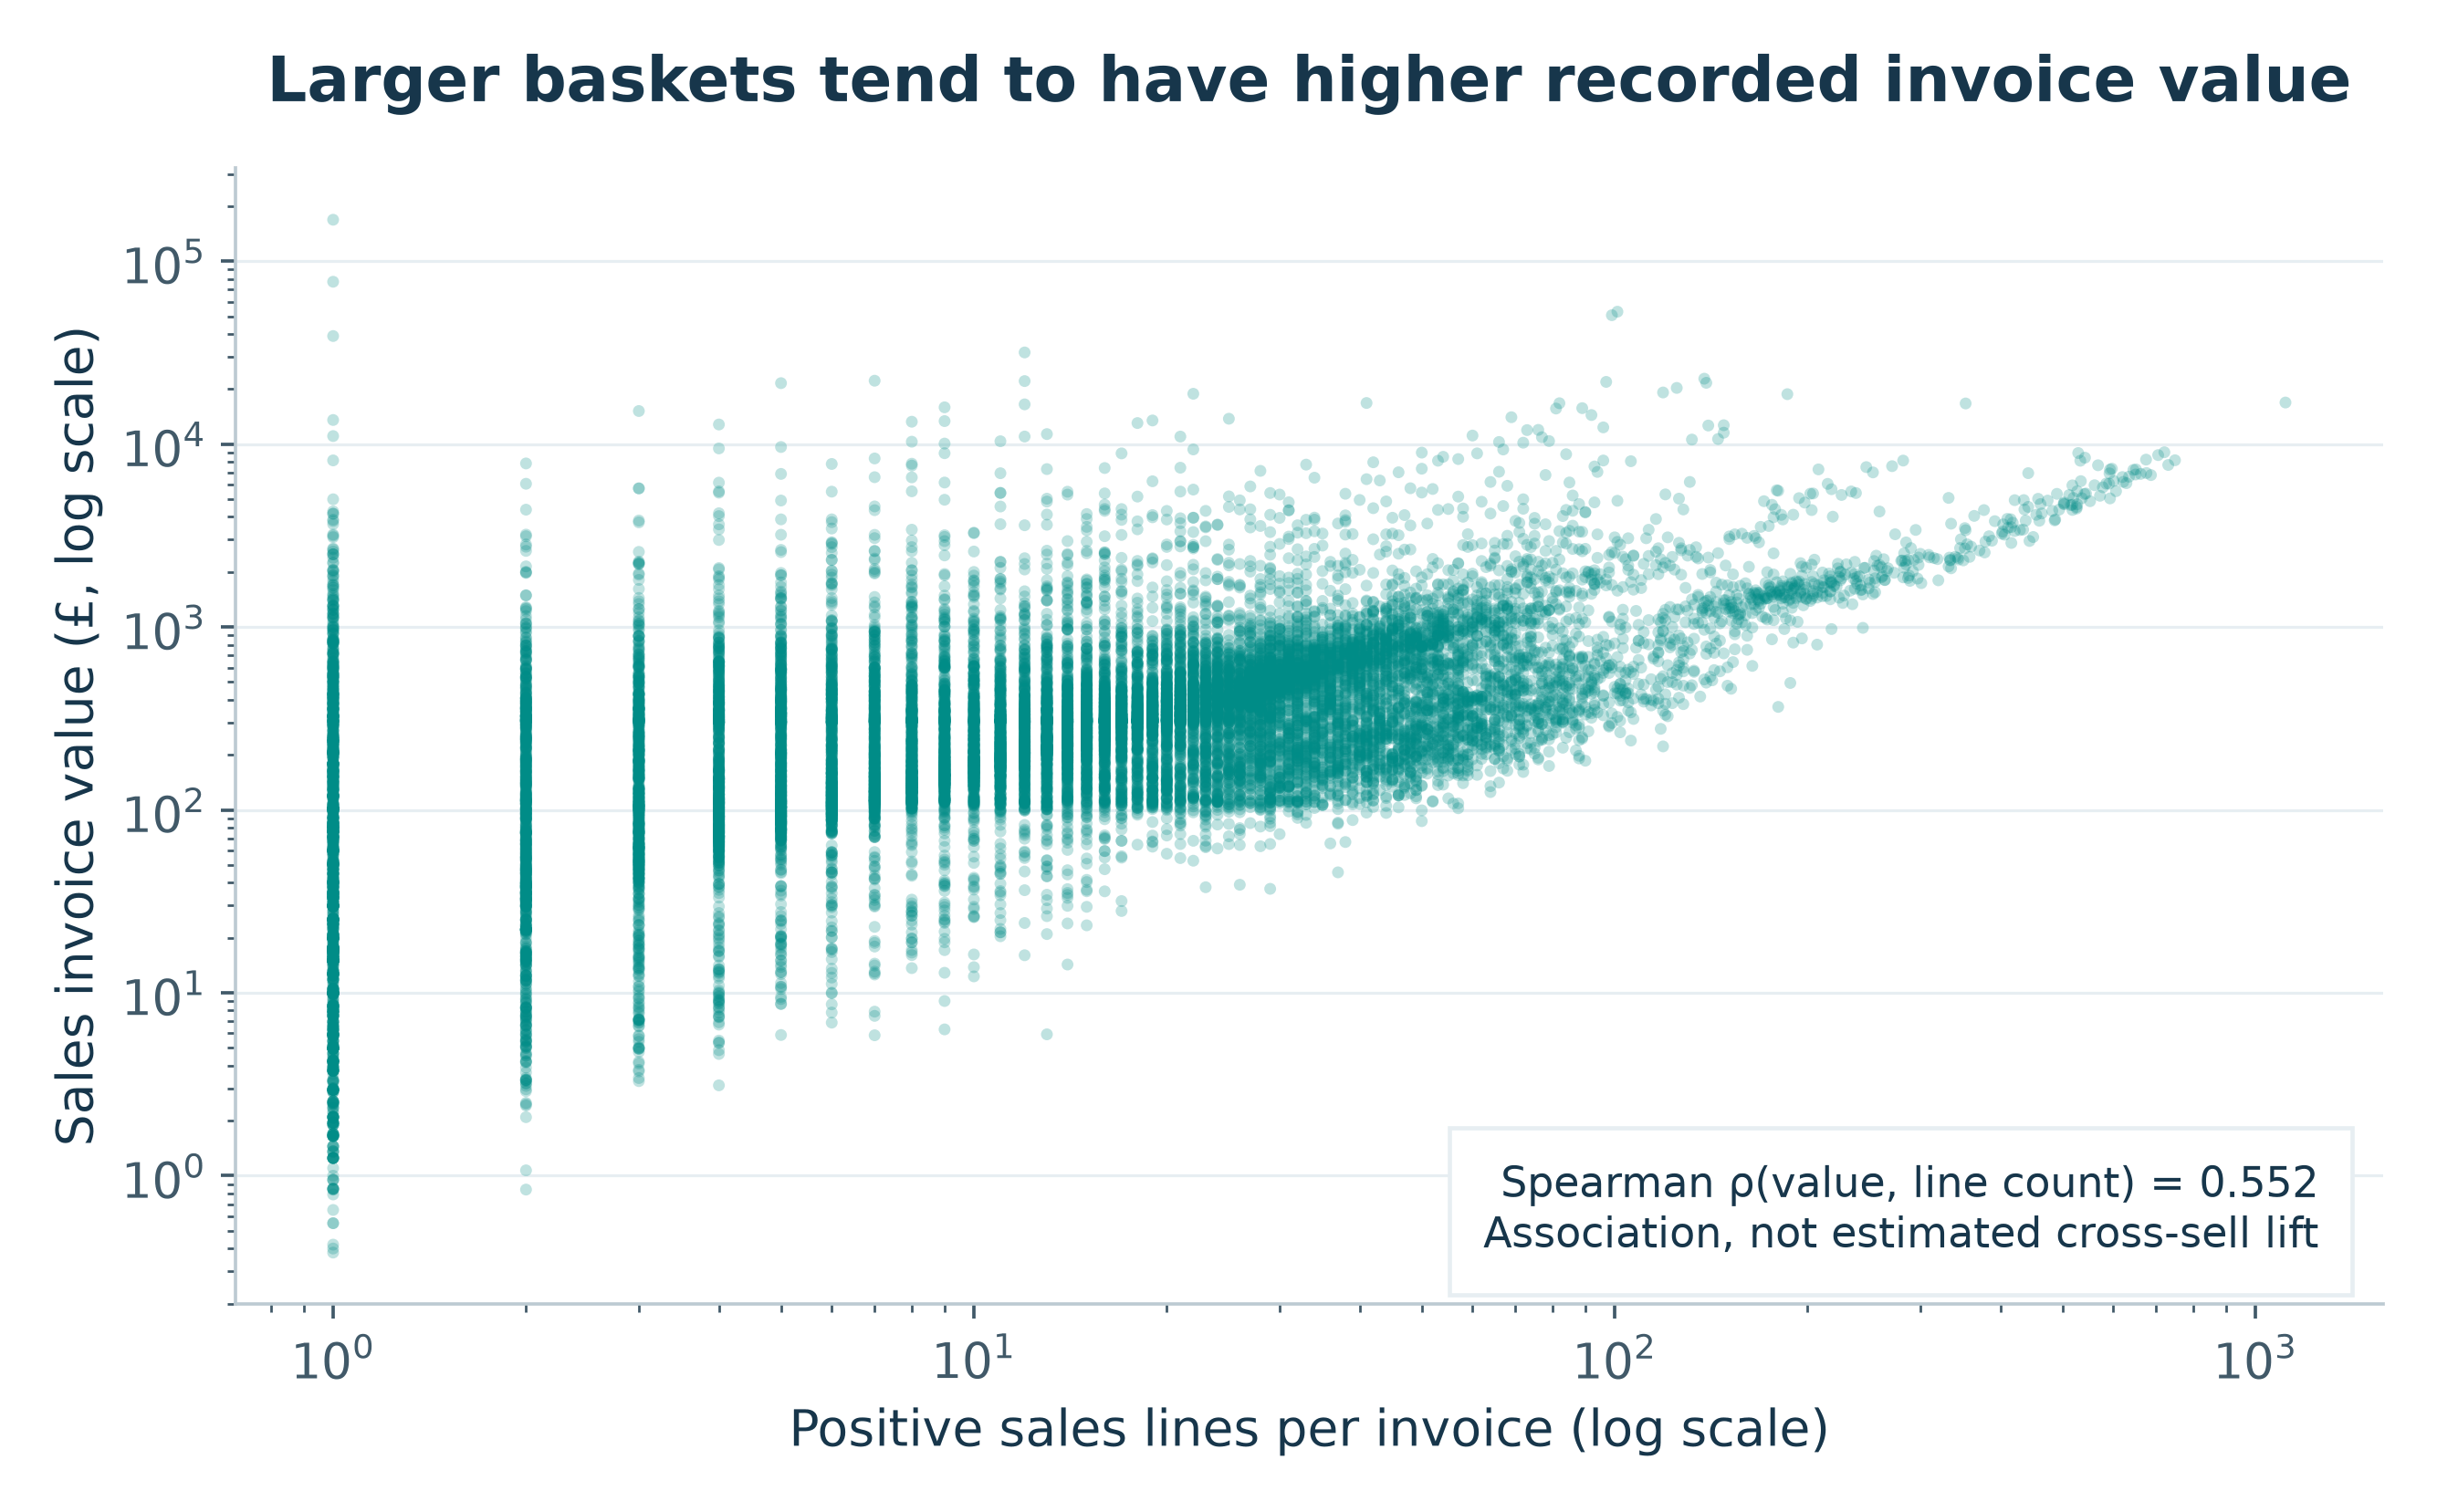

Spearman invoice-level correlation heatmap


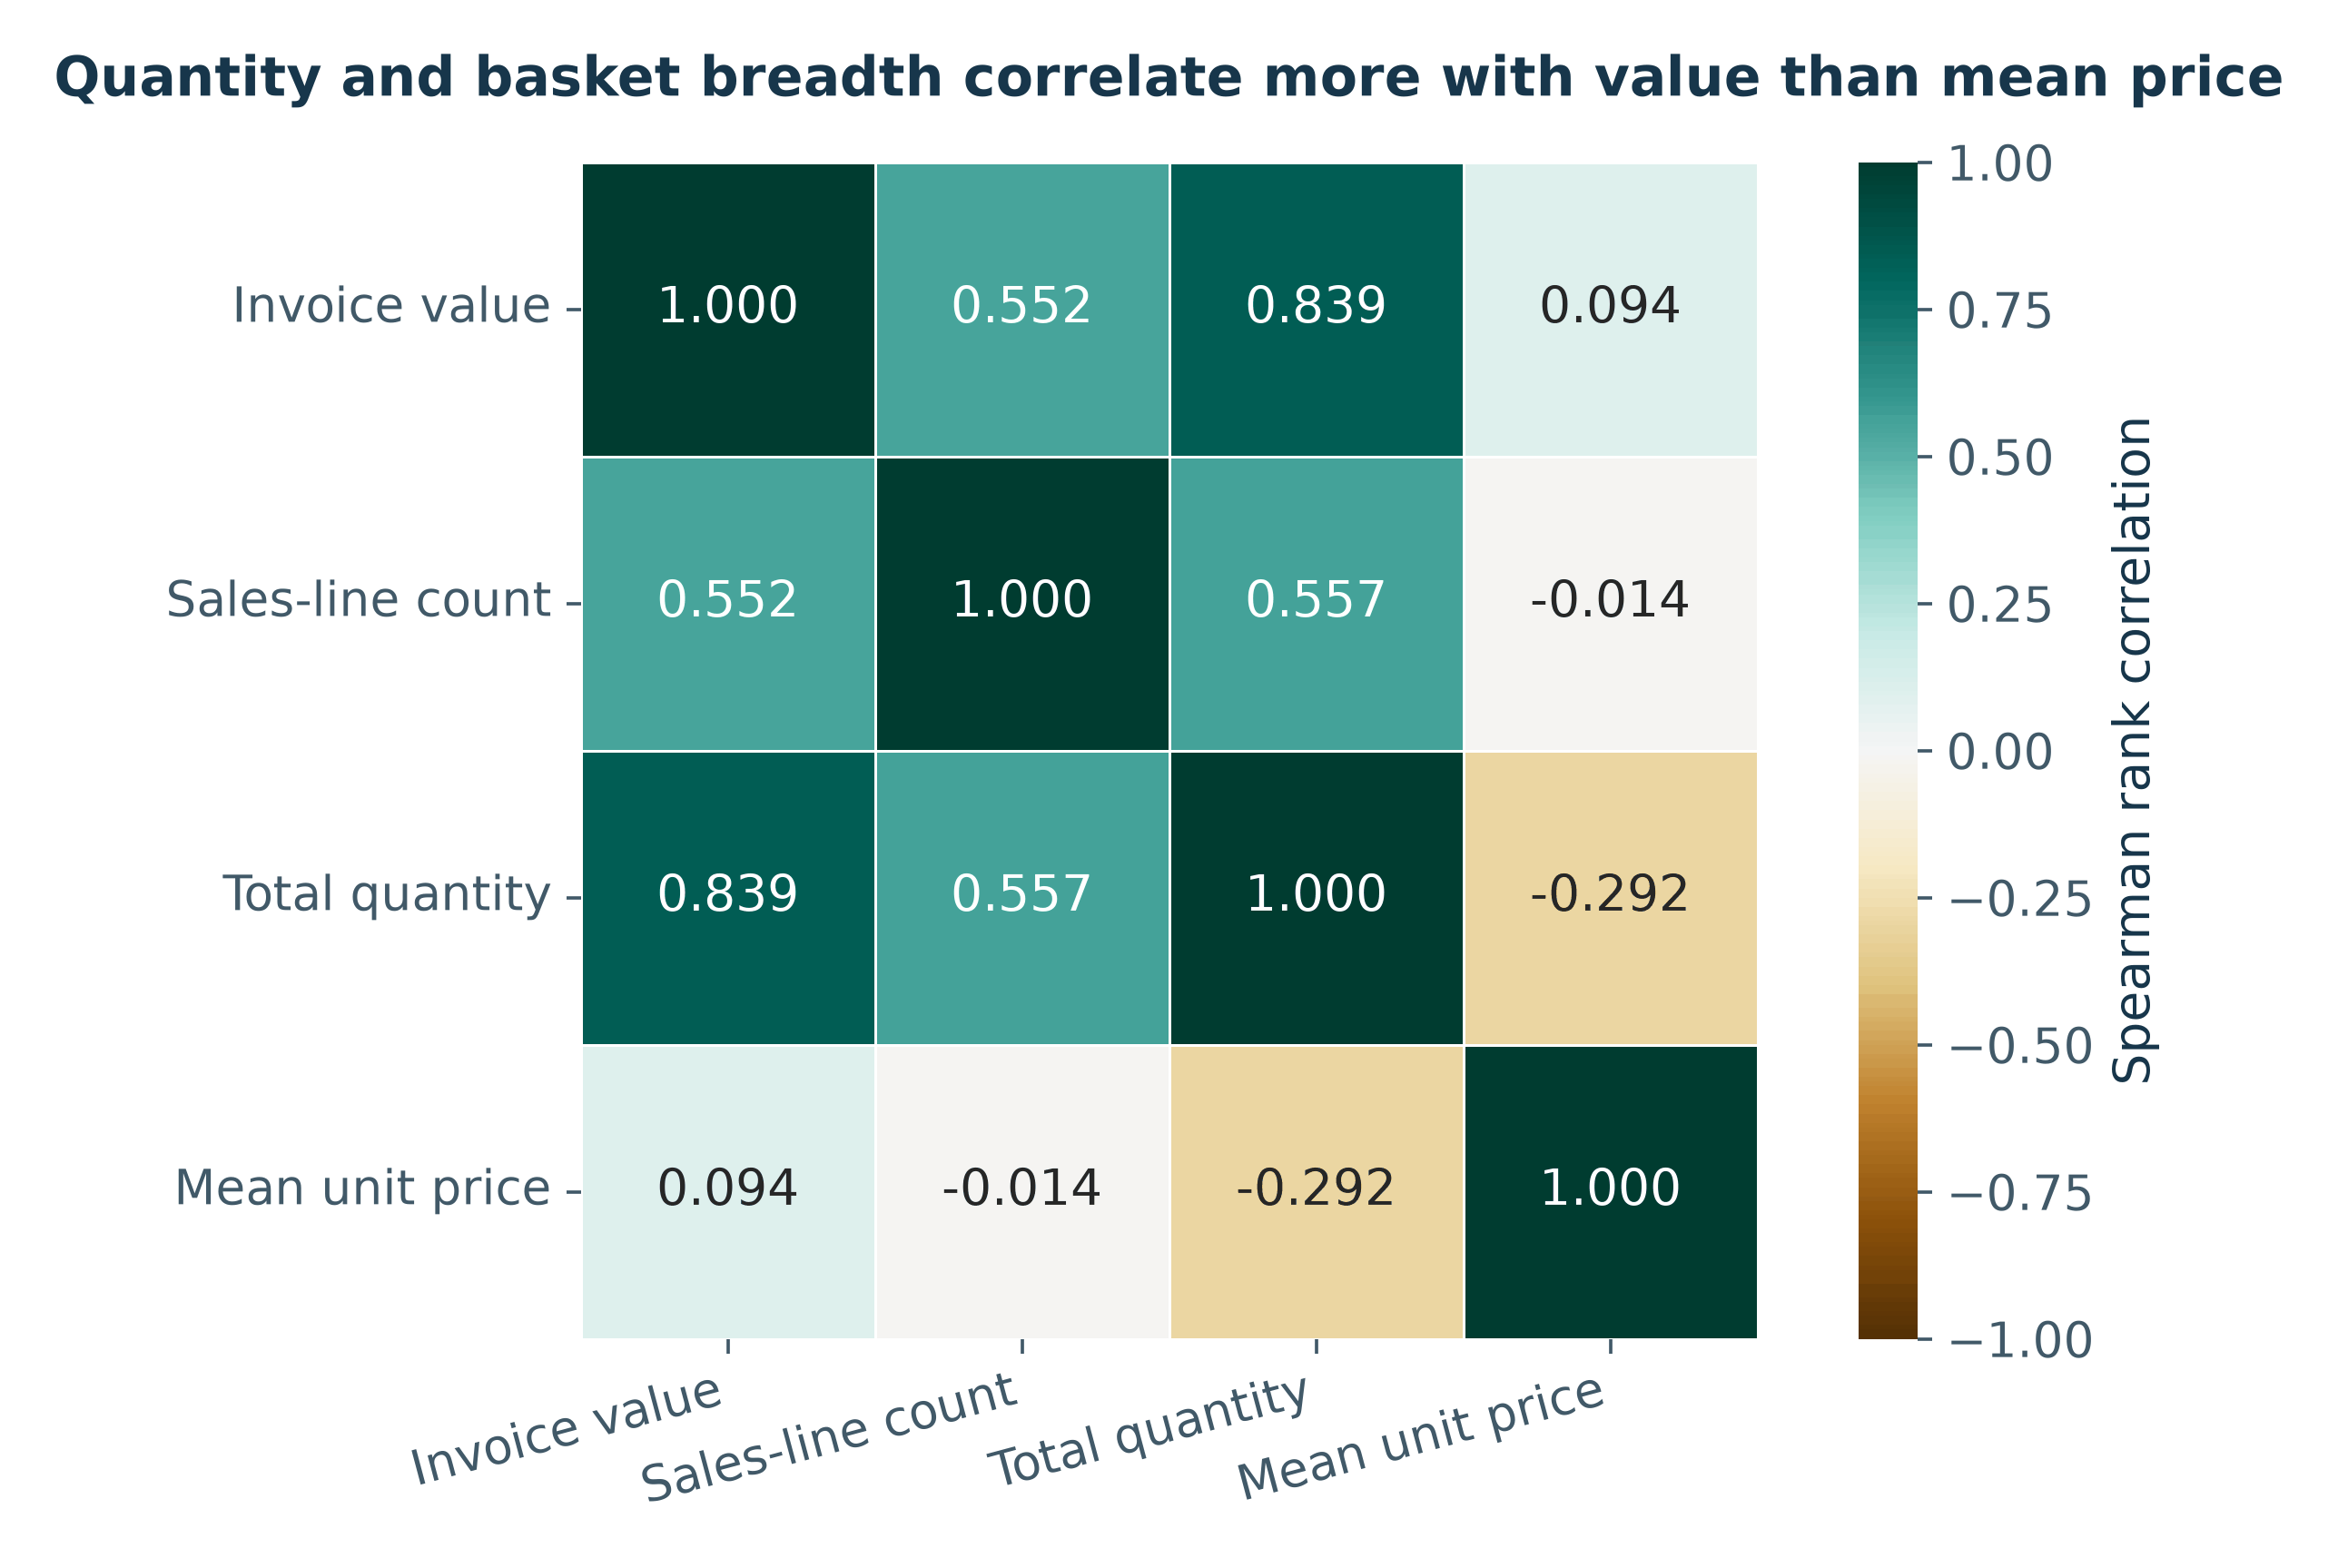

Weekday revenue and mutually exclusive hourly invoice counts


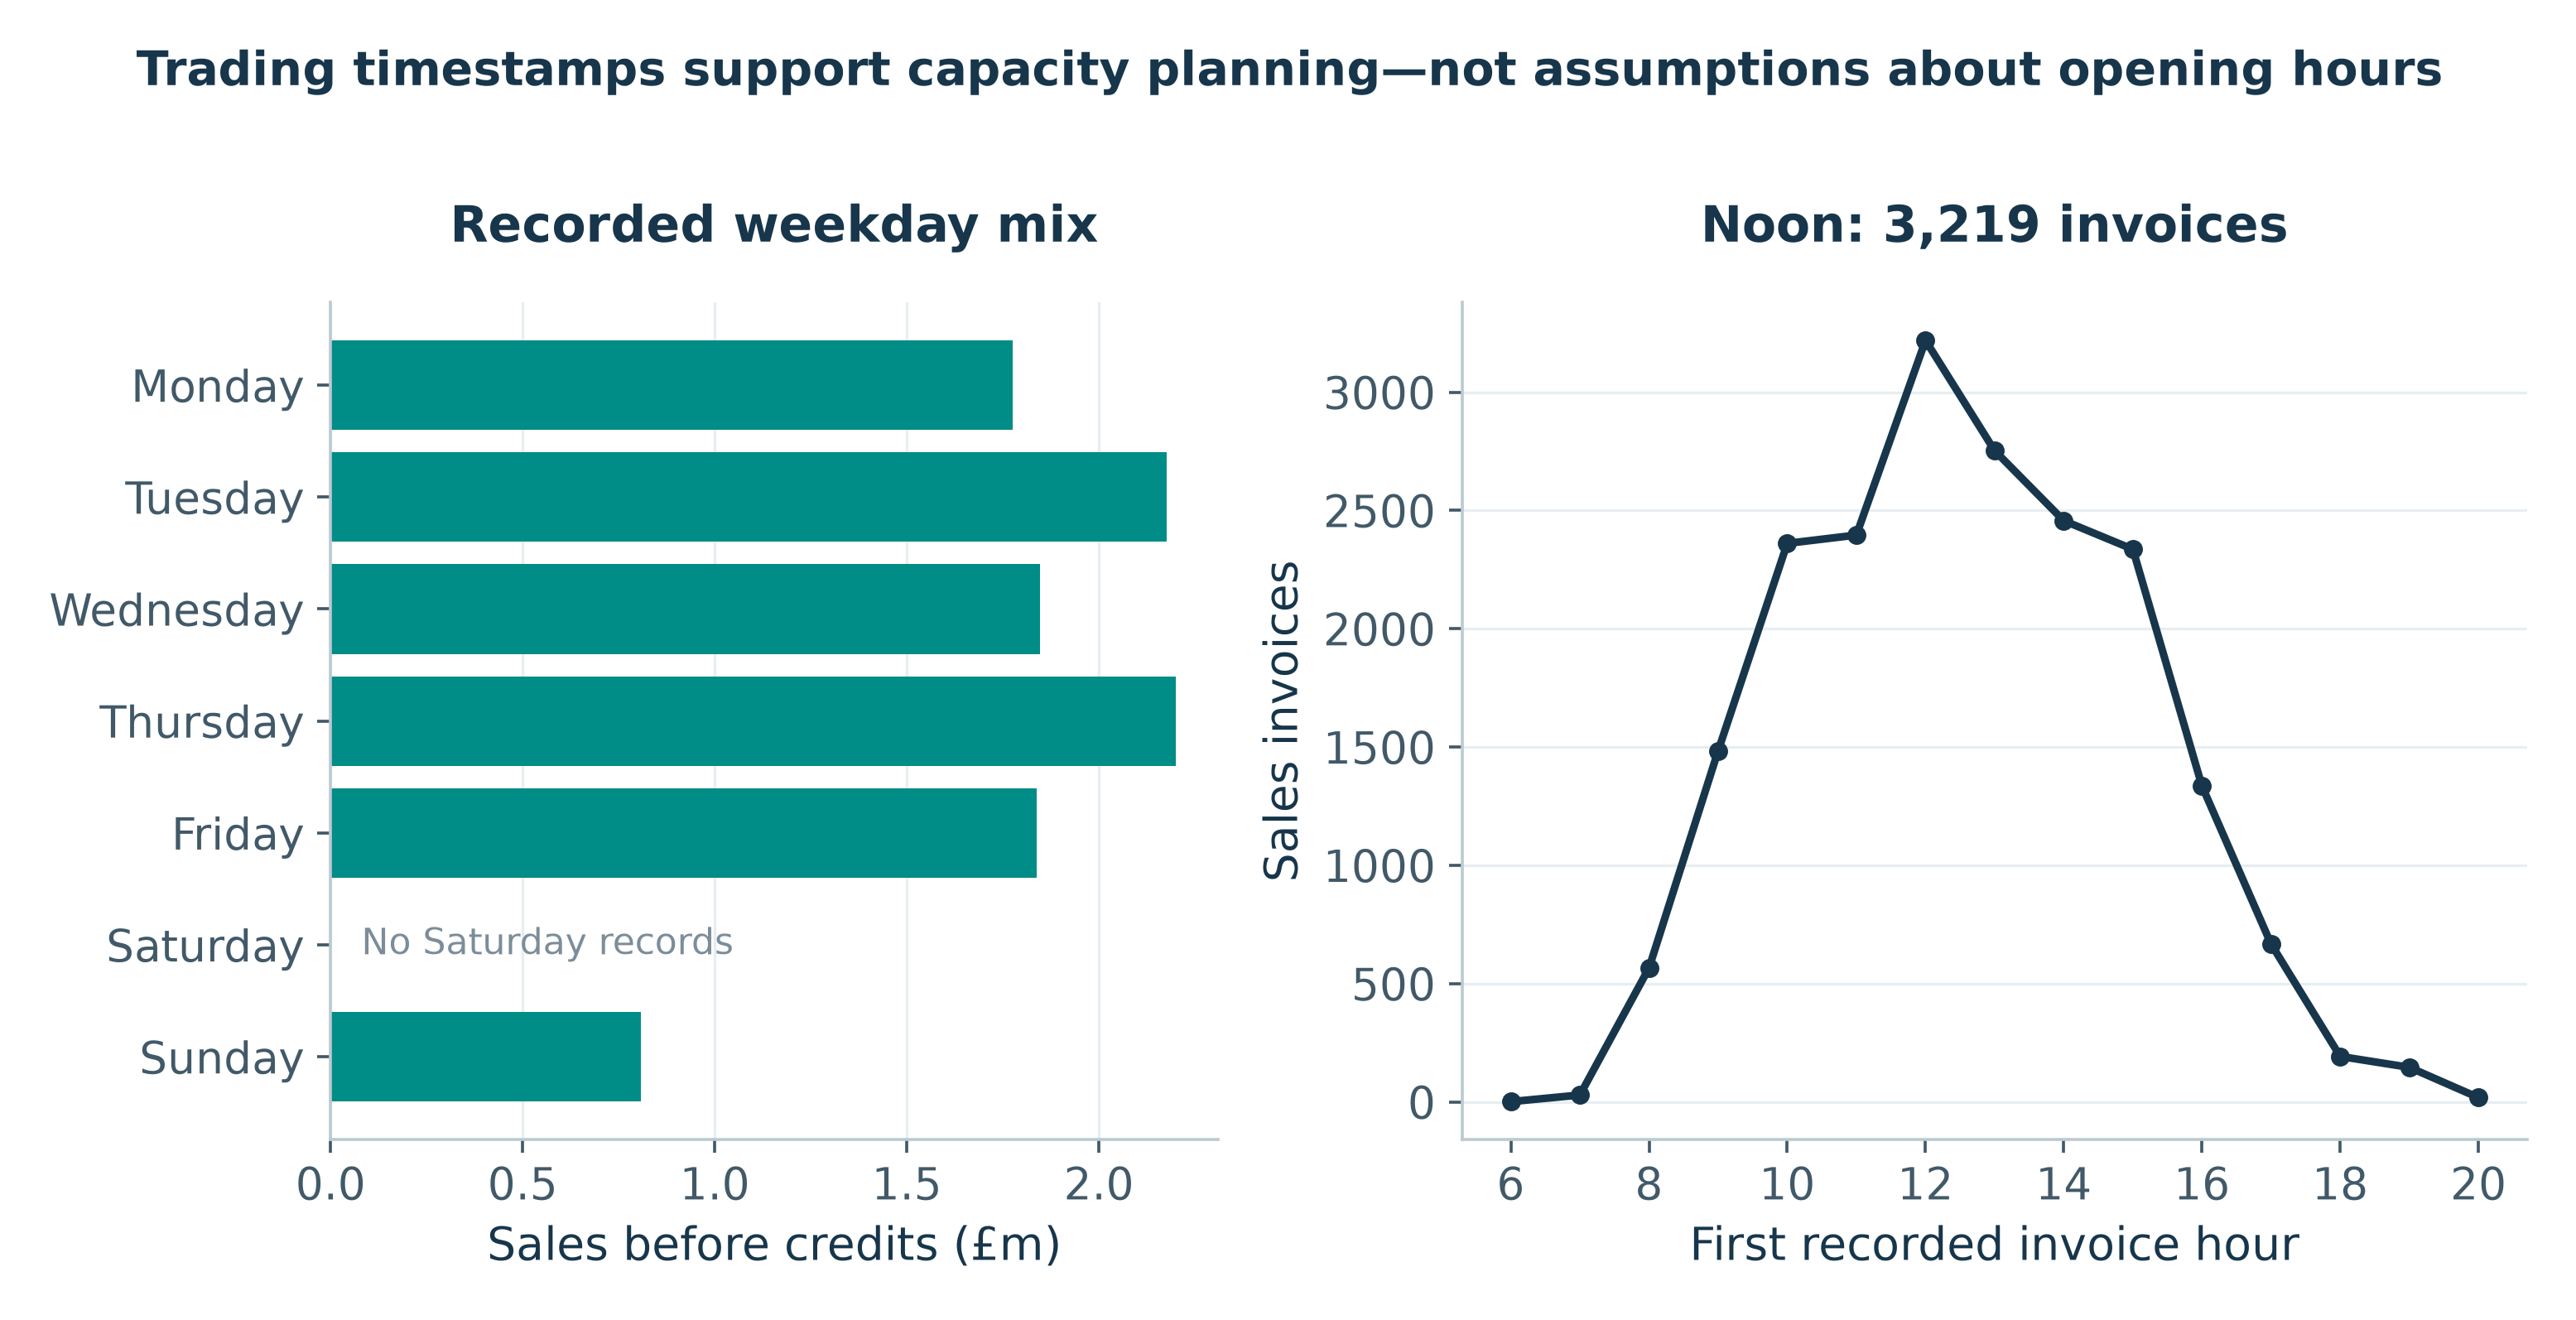

UK and non-UK invoice-value box plots


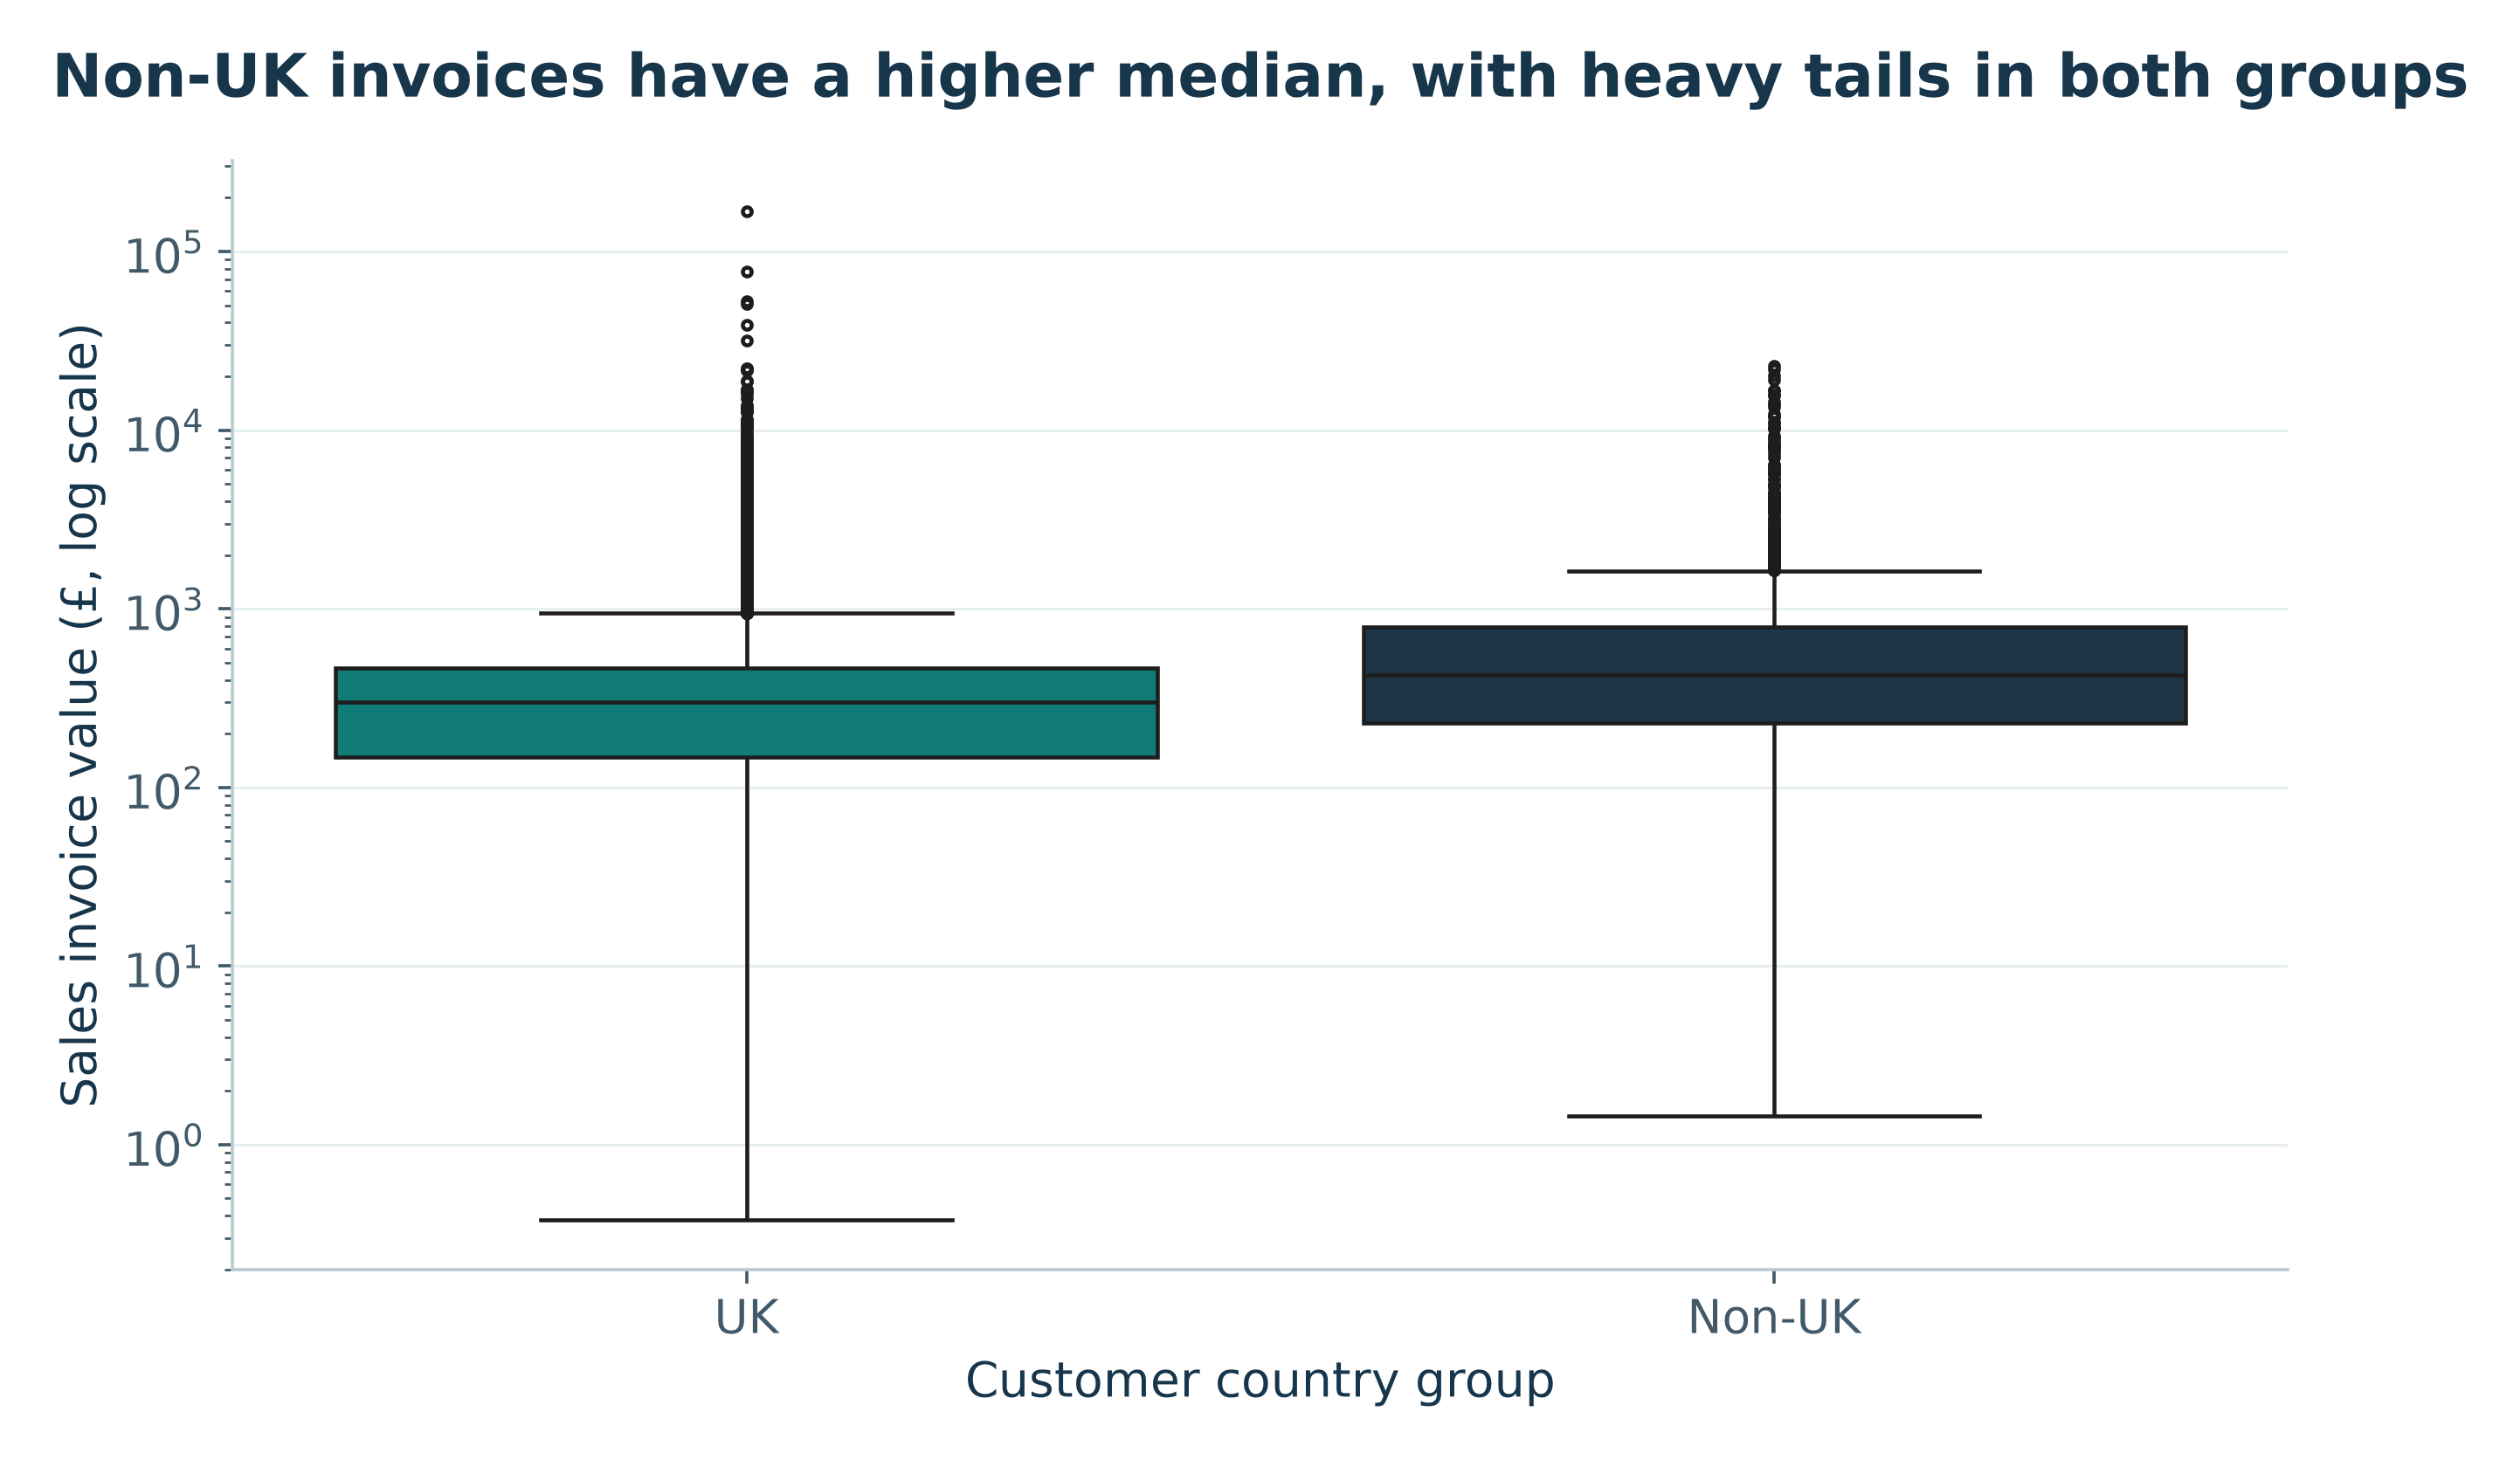

Observed purchase-frequency count plot


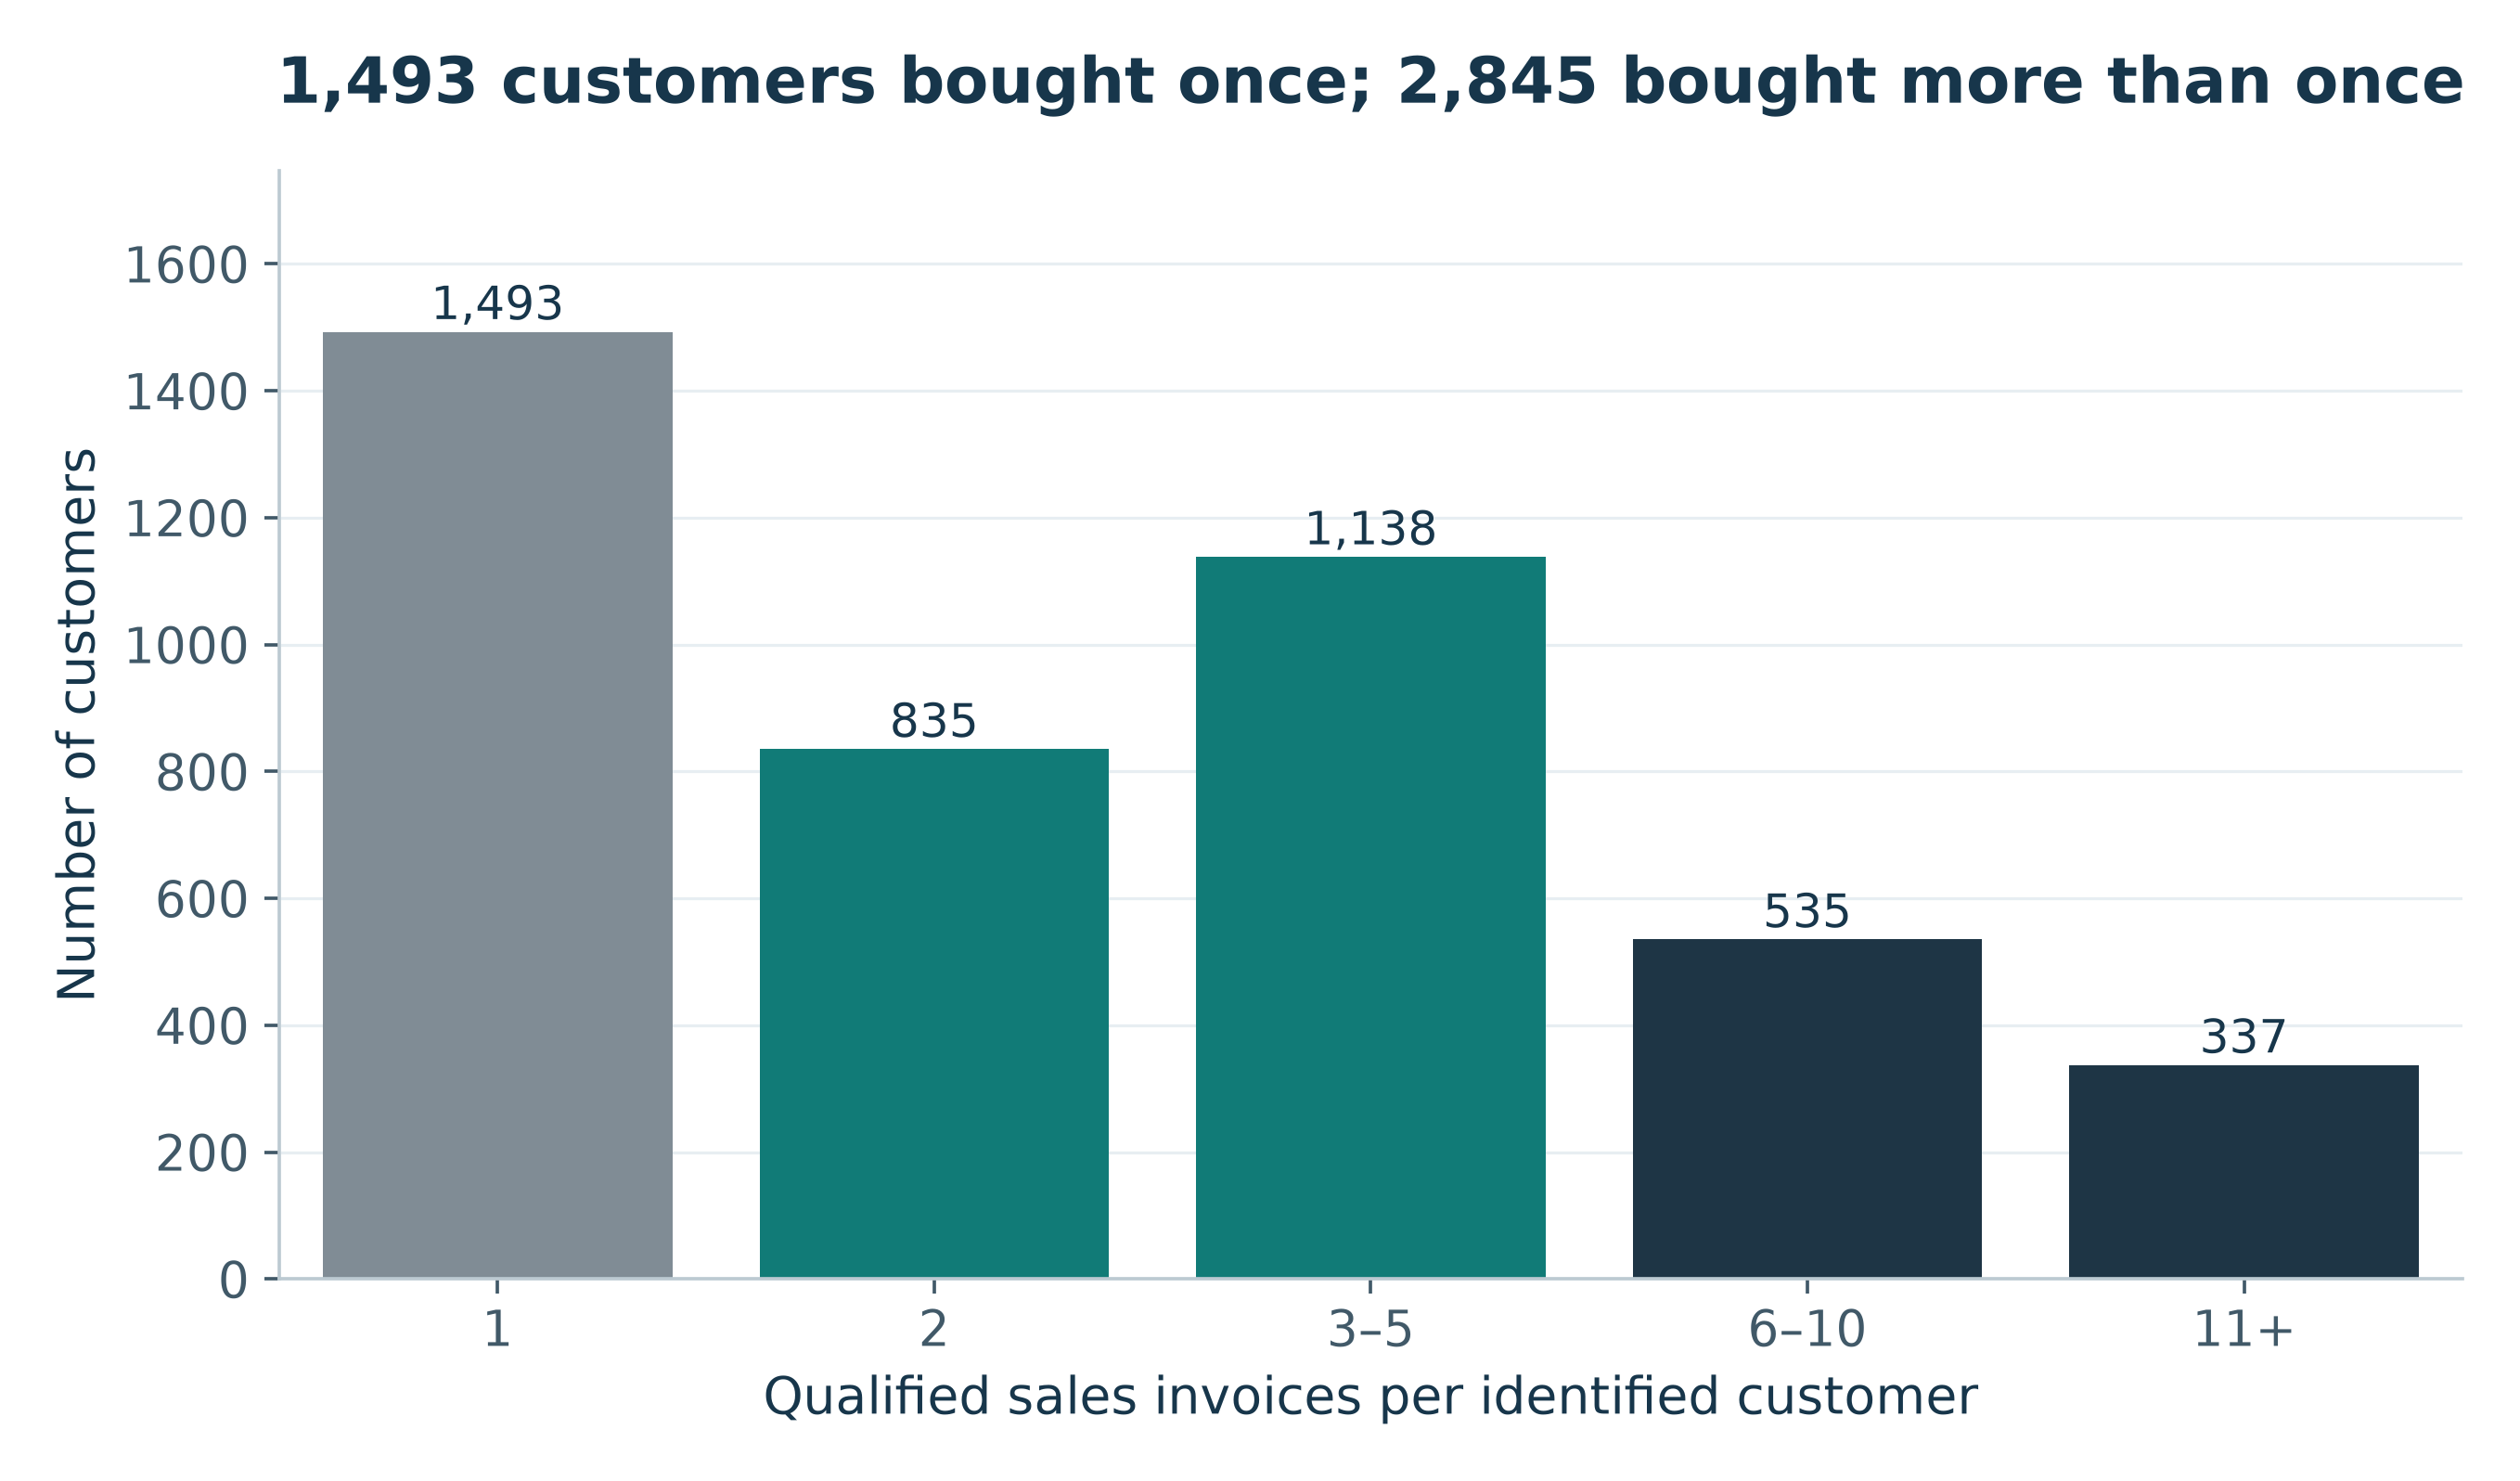

Qualified line quantity and unit-amount histograms


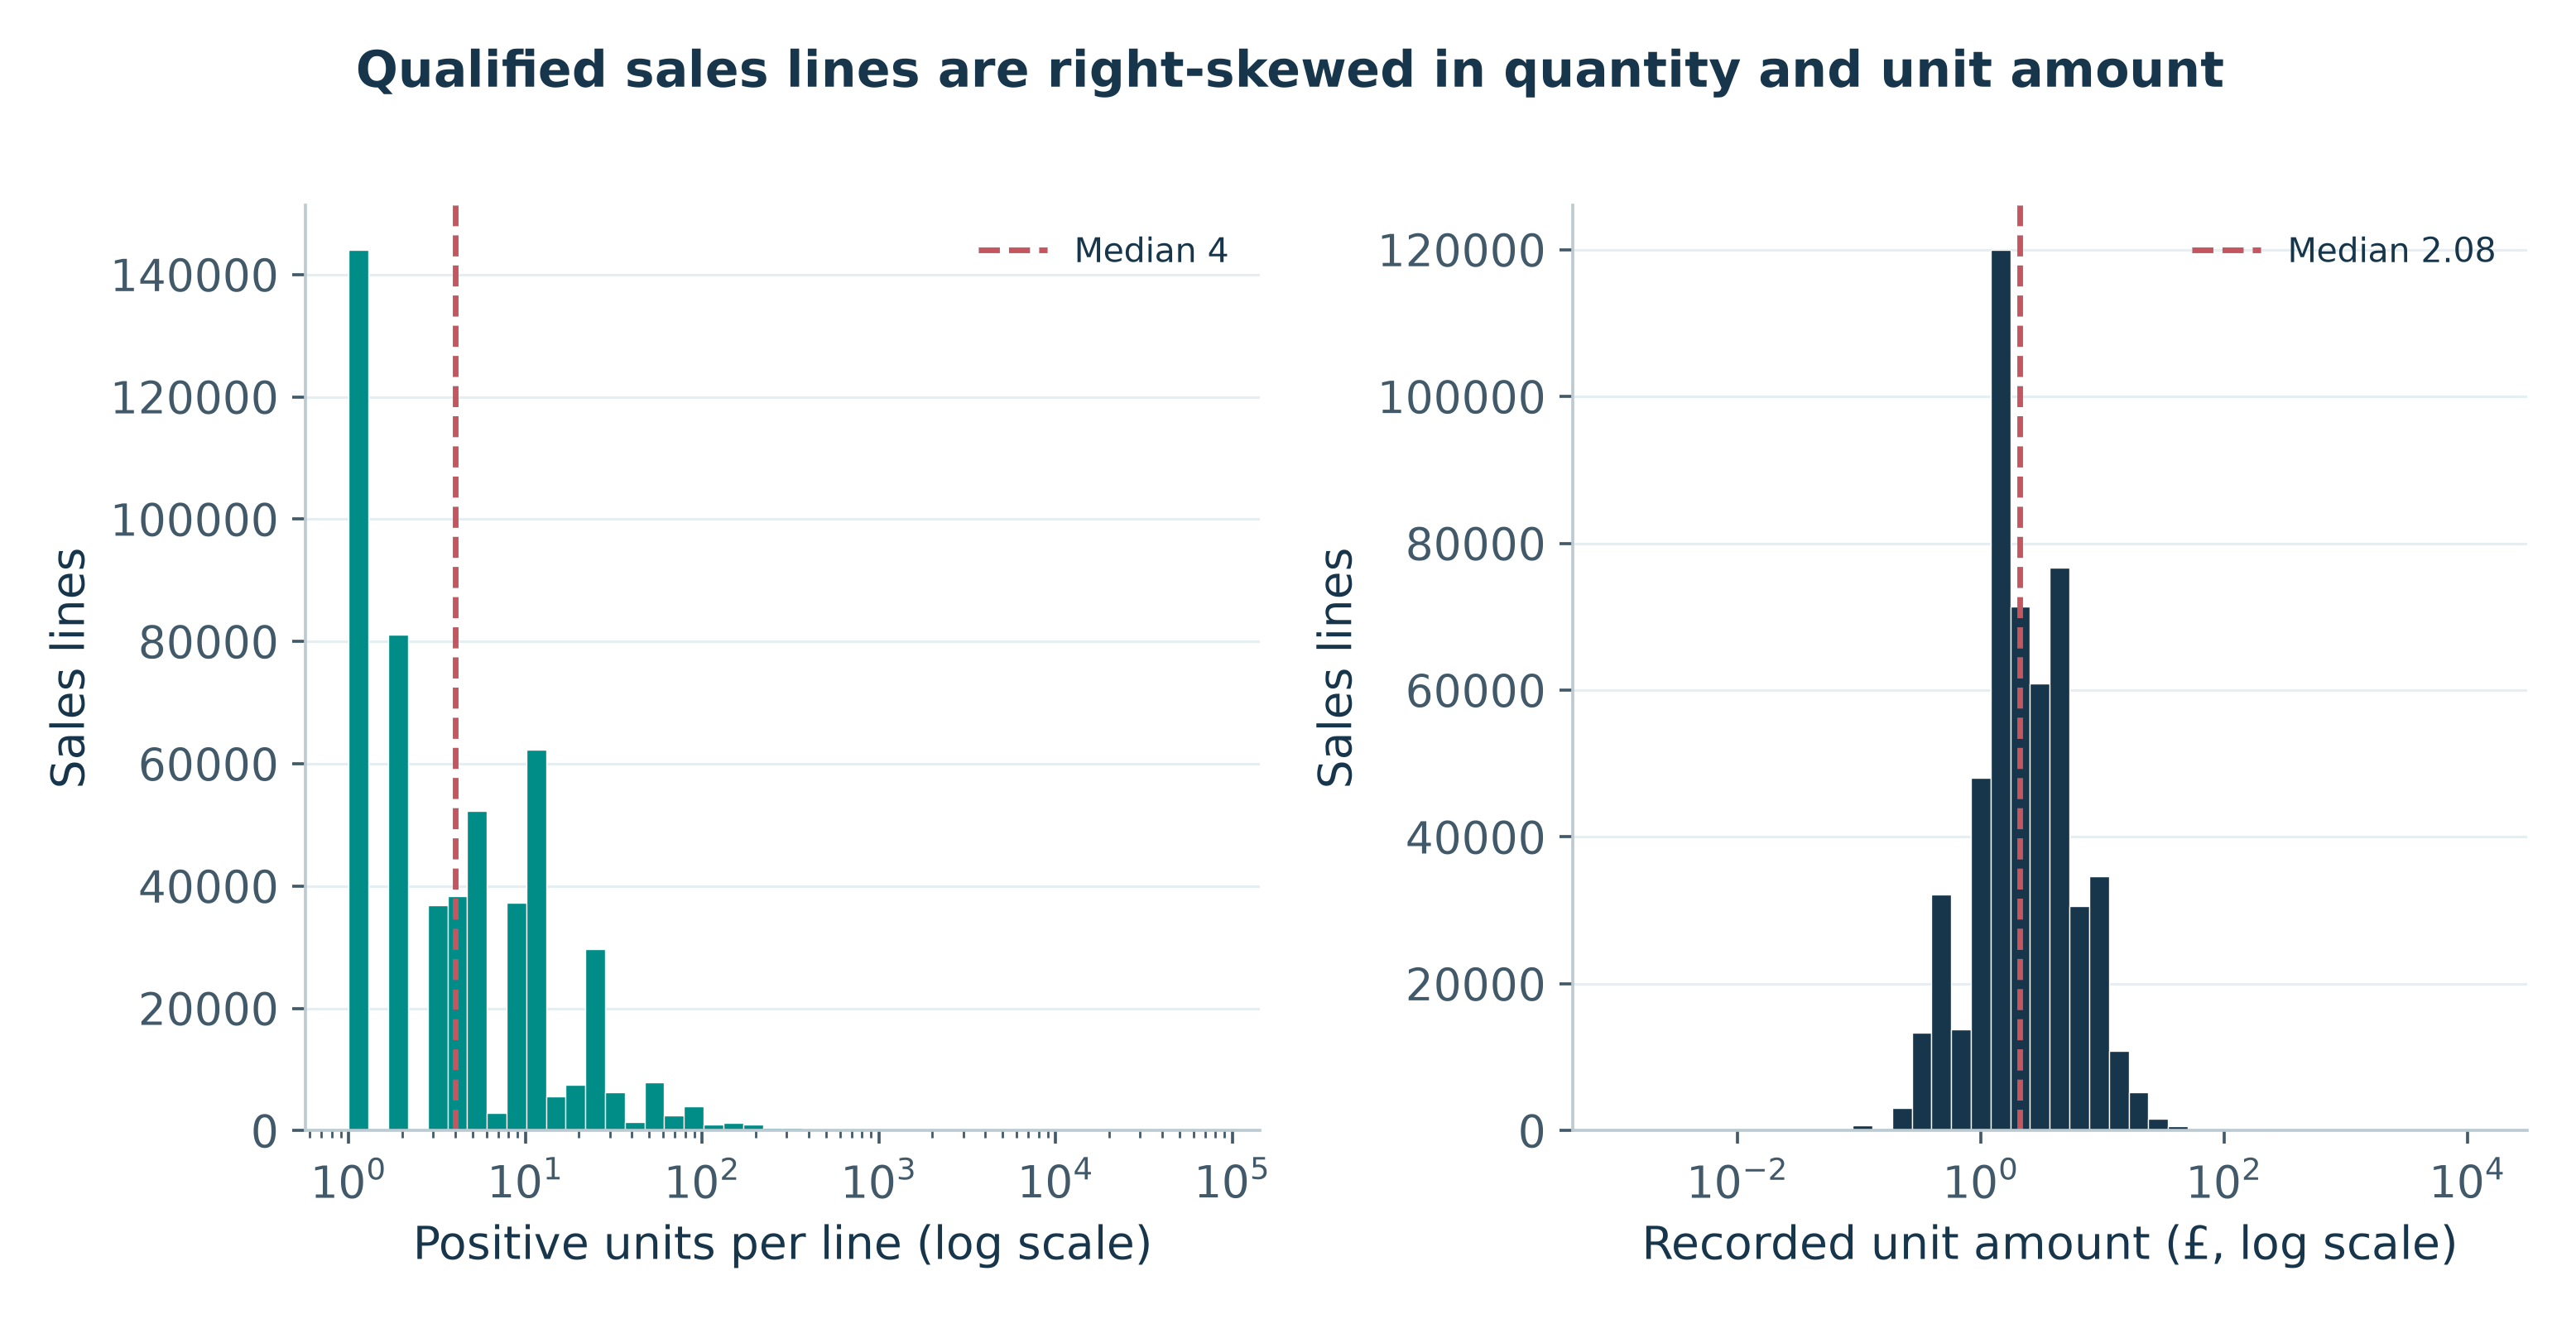

In [12]:
runpy.run_path(str(ROOT/'scripts/make_charts.py'))
gc.collect()
chart_manifest = json.loads((ROOT/'visualizations/chart_manifest.json').read_text())
for item in chart_manifest:
    print(item['title'])
    display(Image(filename=str(ROOT/'visualizations'/item['file']), width=800))

## 12. Cleaned-dataset read-back and exact baseline reconciliation
CSV types are explicit. Missing CustomerIDs stay missing; UNKNOWN means a missing
Description, not a recovered label. All baseline results are independently recomputed.

In [13]:
typed = pd.read_csv(ROOT/'data/cleaned_all_records.csv.gz',
    dtype={'InvoiceNo':'string', 'StockCode':'string', 'CustomerID':'Int64',
           'IsQualifiedSale':'boolean'}, parse_dates=['InvoiceDate'])
assert typed.shape == (536641, 16)
assert typed.SourceRow.is_unique
assert typed.CustomerID.isna().sum() == 135037
assert typed.Description.isna().sum() == 0
assert np.isclose(typed.loc[typed.IsQualifiedSale, 'LineValue'].sum(), m['gross_sales'])
print('Cleaned read-back:', typed.shape, '| qualified:', typed.IsQualifiedSale.sum())
display(pd.read_csv(ROOT/'outputs/task4_metric_reconciliation.csv'))
print('PASS: all 24 baseline comparisons match.')

Cleaned read-back: (536641, 16) | qualified: 524878


,Metric,OriginalTask4,RevisedTask4,Difference,Status
0,Raw rows,541909.00,541909.00,0.0,MATCH
1,Raw columns,8.00,8.00,0.0,MATCH
2,Duplicates,5268.00,5268.00,0.0,MATCH
3,Valid sale lines,524878.00,524878.00,0.0,MATCH
4,Valid invoices,19960.00,19960.00,0.0,MATCH
5,Identified customers,4338.00,4338.00,0.0,MATCH
6,Sales before credits,10642110.80,10642110.80,0.0,MATCH
7,Units before credits,5572420.00,5572420.00,0.0,MATCH
8,AOV before credits,533.17,533.17,0.0,MATCH
9,Repeat rate (%),65.58,65.58,0.0,MATCH


PASS: all 24 baseline comparisons match.


## Conclusions and limitations
Sales before credits are £10,642,110.80; credit-adjusted value is £9,748,131.07.
Fully offset extremes, missing IDs, customer/country concentration and partial-month
coverage are central to interpretation. Actions are proposals and require current data.
No causal driver, profit, ROI, uplift or forecast recovery is demonstrated.

The Word report contains all 19 sections, 14 fully worked examples, 12 evidence-backed
insights and 8 measurable recommendations. `tests/validate_outputs.py` independently
checks workbook integrity, row/financial identities, worked calculations and deliverables.
